Students: Lorenzo Messali and Francesco Castelnuovo
GitHub: https://github.com/lorenzomessali3/ASPO-Lab/tree/main/lab1


 Copyright © Sorbonne University.

 This source code is licensed under the MIT license found in the
 LICENSE file in the root directory of this source tree.

# Outlook

In this notebook, we study basic linear and non-linear regression algorithms.
Regression is another name for function approximation, it consists in fitting a function to a set of points, as shown below.

The notebook is meant to study elements presented in lessons available in video here 
https://www.youtube.com/playlist?list=PLe5mY-Da-ksURGcelU-egwtWZXxVgZ76a

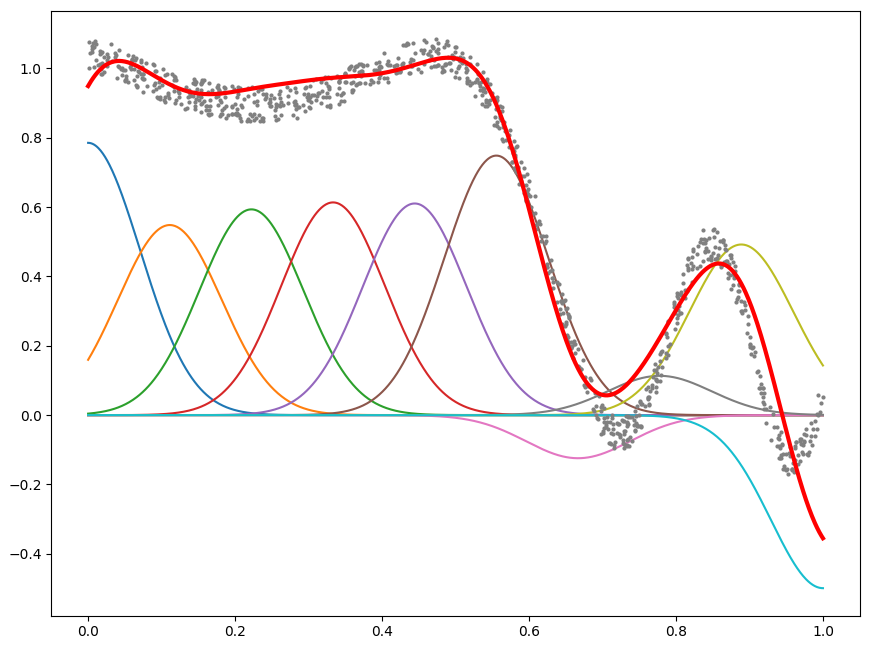


The notebook contains coding parts, where you have to code the main regression algorithms and check they work with a visualization,
and study parts, where you investigate their properties when changing some parameters or where you perform comparisons between methods. 
The study part may involve further coding to generate appropriate diagrams.

There are more studies than doable in a short time.
Do what you can among the studies. 
Doing one study accurately is better than being inaccurate on all studies.


# Installation

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt

%pip install -q git+https://github.com/osigaud/regressionLabs

from regression_labs.batch import Batch
from regression_labs.latent_function import LinearLatentFunction, NonLinearLatentFunction, NonLinearLatentXDFunction
from regression_labs.gaussians import Gaussians

/Users/lorenzomessali/Desktop/UNIBS/PARIGI DOPPIO TITOLO /SORBONNE CLASSES/APCO/LAB APCO/Lab1_valutato/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


# Introduction

The objective of regression or function approximation is to create a model from observed data. 
The model has a fixed structure with parameters (like the coefficients of a polynomial for instance), 
and regression consists in adjusting these parameters to fit the data. 
In machine learning, it is a very important technique since having a good model enables better predictions and performance.

With mathematical notations, given some datapoints $\{ ({\bf x}, {\bf y}) \}$, 
the goal is to adjust a model ${\bf y} = f({\bf x})$ so that the *learned* function $f$ accounts for these datapoints 
and generalize well to other unseen points $\{ ({\bf x}, {\bf y}) \}$.

The simplest case is linear regression, which assumes a relation of type ${\bf y} = {\bf A}{\bf x} + {\bf b}$ 
between the data ${\bf x}$ and ${\bf y}$.

Several methods exist to adjust the parameters ${\bf A}$ and ${\bf b}$, 
the most well-known being the least squares method (or least norm in the multivariate case).

In this lab, we assume that ${\bf y}$  is of dimension 1 (and write $y$ instead of ${\bf y}$  in what follows). 
This is a very common assumption.

Furthermore, in the code ${\bf x}$ is also of dimension 1, this is more restrictive 
as regression is often used from multidimensional input data.

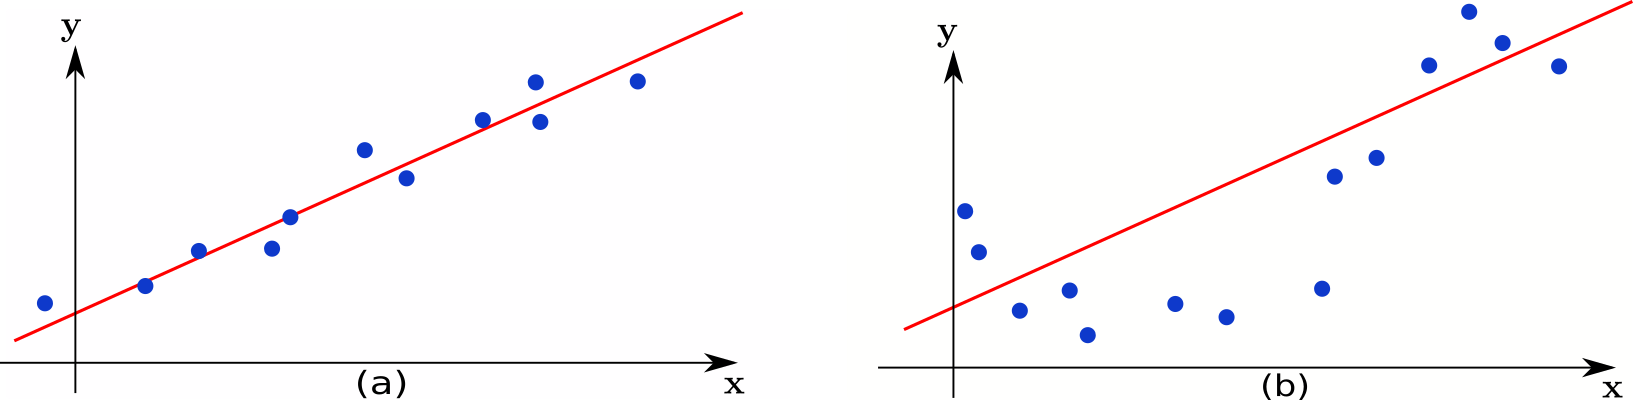


Often, linear models are not enough. For instance, see figures (a) and (b) above, 
on the left a linear regression is OK, but on the right it is not. 
In the case of (b), we must rely on nonlinear models. 
Here, we focus on the case where $f$ can be written as a sum of $k$ functions parametrized by vectors ${\boldsymbol{\theta}}_i$:

$$ f({\bf x})  = \sum_{i=1}^k f_{\boldsymbol{\theta}_i}({\bf x}).$$

In particular, we use Gaussian functions.

## Weighted sums of Gaussian functions

Gaussian functions $\phi_i({\bf x}) = \exp(-\frac{({\bf x}-{\bf c_i})^2}{\sigma_i^2})$ are almost equal to zero 
everywhere except in a neighborhood of ${\bf c_i}$, which represents the "center"' of the Gaussian (see the figure below). 
The value of $\sigma_i$ determines how large this neighborhood is.

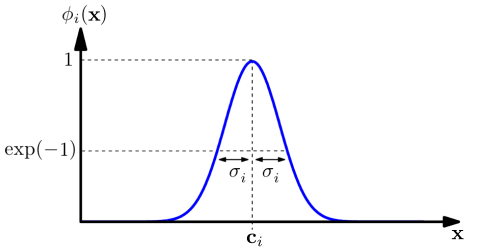

Then weighted Gaussian functions $f_{\boldsymbol{\theta}_i}$ can be written:

$$ f_{\boldsymbol{\theta}_i} = {\bf \theta}_i \phi_i({\bf x}) = {\bf \theta}_i \exp\left(-\frac{({\bf x}-{\bf c_i})^2}{\sigma_i^2}\right). $$

In RBFNs, the centers of the Gaussian functions are fixed in advance, and evenly distributed in the input space. 
Besides, all the $\sigma_i$'s are usually set to the same value.
Thus weighted Gaussian functions $f_{\boldsymbol{\theta}_i}$ have a unique scalar parameter 
which is their vector of weights $\boldsymbol{\theta}_i$.

# Provided code and documentation

The numpy reference guide is here: http://docs.scipy.org/doc/numpy/reference/

We provide a few useful classes and the infrastructure to perform these labs.

## Data generation

Two functions to generate points corresponding to a noisy linear and a noisy nonlinear model are provided in 
the ```LatentFunction``` class in the 
[latent_function.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/latent_function.py) file.

## Batch of data

The [batch.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/batch.py) file contains 
the ```Batch``` class. This class is used to collect a batch of linear or non-linear data, either in a single batch or incrementally.

## Vectors of Gaussian functions

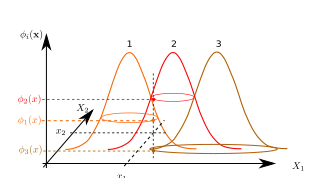

A ```Gaussians``` class is provided in [gaussians.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/gaussians.py) 
to represent a vector of Gaussian feature functions $\phi({\bf x})$ of an input vector ${\bf x}$, 
as used in RBFNs and Locally Weighted Regression (LWR) (see below). 
The number $E$ of elements of $\phi({\bf x})$ (i.e. the number $E$ of Gaussian functions) is defined by the ```nb_features``` attribute. 

Given some input vector ${\bf x}$, the function ```phi_output(x)``` returns 
the vector of the output of (non-weighted) Gaussian functions applied to ${\bf x}$, thus a vector of size $E$.
In the particular case where $x$ is a scalar, it is transformed into a one element vector to keep consistent with the N-dimensional case.

Note that the input of the (multivariate) Gaussian functions is of the same dimension as ${\bf x}$, 
but their output is one-dimensional (see the figure above).

## Function approximators

We consider three families of approximation models: linear models , radial basis function networks and locally weigthed regression models. 
In all these models, the theta attribute represents the vector of parameters to be optimized. 
The ```f(self, x)``` function represents the function approximator output for a given input ```x```, to be optimized. 
The parameters used by $f$ are the elements of the ```theta``` vector.

For instance, for RBFNs, we consider a vector of $E$ Gaussian functions 
$\phi({\bf x}) = (\phi_1({\bf x}) \ \phi_2({\bf x}) \cdots \phi_E({\bf x}))^\intercal$, 
a vector of weights $\boldsymbol{\theta} = (\boldsymbol{\theta}_1 \ \boldsymbol{\theta}_2 \cdots \boldsymbol{\theta}_E)^\intercal$, 
and a vector of weighted Gaussian functions $f({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$.

These function approximation models come with various ```train_...(self, ...)``` functions that you must fill.

# Visualization

For all the regression methods described below, as illustrated in the figure at the top of this notebook, 
after executing it, the observed data are shown by points, and the red curve is the *learned* function $f$ 
corresponding to the parameters $\boldsymbol{\theta}$ that have been incrementally adjusted. 
When this applies, the other curves correspond to the $f_{\boldsymbol{\theta}_i}({\bf x})$ functions, 
they show the decomposition of $f$, which is the sum of all these functions. 
All visualization functions are in the ```plot()``` function of each approximator.

# Notations and code helpers

We consider either a batch regression approach, an iterative one or an incremental one. In the batch and iterative approaches, we consider a batch of data consisting of $N$ $\{ ({\bf x}_i, y_i) \}_{1 \leq i \leq N}$ pairs.
In the incremental one, we get an additional pair of data $({\bf x}^{(t)}, y^{(t)})$ at each time step $t$.

In the general case, an input datapoint ${\bf x}$ is of dimension $d$, and we have ${\bf x} = (x_1 \ x_2 \cdots x_d)^\intercal$.
Under algebraic form, the batch of data is rewritten $({\bf X}, {\bf y})$ where ${\bf X}$ is a $N \times d$ matrix and ${\bf y}$ is a $N$ dimensional vector.

## Issues with ```transpose()``` in numpy

In regression algorithms, we often use the transpose operator.
But in numpy, transposing a standard one-dimensional vector does not work as expected: the result of the tranpose operator is the same vector, which is quite unfortunate.

Below we define two functions to fix this issue.

In [5]:
import numpy as np

def horiz_to_verti(vec):
  return vec.reshape(-1, 1)

def verti_to_horiz(vec):
  return vec.reshape(-1)

And here is a small example about how to use it.

In [6]:
vec = np.zeros(3)
print(vec)
v2 = vec.transpose()
print ("incorrect transpose:", v2)
v3 = horiz_to_verti(vec)
print ("correct transpose:", v3)
v4 = verti_to_horiz(v3)

print ("transpose of the transpose:", v4)

[0. 0. 0.]
incorrect transpose: [0. 0. 0.]
correct transpose: [[0.]
 [0.]
 [0.]]
transpose of the transpose: [0. 0. 0.]


## Augmenting the design matrix with one dimension

To solve a linear least square problem, we want to use a model of the form $f_\boldsymbol{\theta}({\bf X}) = \boldsymbol{\theta}^\intercal{\bf X} + {\bf b}$.
To deal more elegantly with the intercept ${\bf b}$, we extend the vectors ${\bf x}$ with an additional dimension
using $\bar{\bf x}_i = (x_{i,1} \ x_{i,2} \cdots x_{i,d} \ 1)^\intercal$, and we redefine the augmented design matrix as

$$\bar{\bf X}=\left(
\begin{array}{ccccc}
 x_{1,1}&x_{1,2}&\cdots &x_{1,d} &1\\
 x_{2,1}&x_{2,2}&\cdots &x_{2,d} &1\\
 \vdots  &\vdots  &\ddots &\vdots   &\vdots\\
 x_{N,1}&x_{N,2}&\cdots &x_{N,d} &1\\
\end{array}
\right).
$$

This way, our model can be rewritten $f_\boldsymbol{\theta}({\bf X}) = \boldsymbol{\theta'}^\intercal{\bar{\bf X}}$.

From the list of vectors *x_data* provided by the sample generator, $\bar{\bf X}$ can be obtained by first transforming *x_data* into a *numpy array* and transposing using

```x_data = numpy.array(x_data).transpose()```,

and then adding the ones with:

```barX = np.hstack((x_data, numpy.ones((x_data.shape[0], 1))))```

Let us define the ```bar_design()``` function

In [7]:
def bar_design(x):
  return np.hstack((x, np.ones((x.shape[0], 1))))

And check that it works.

In [8]:
lf = LinearLatentFunction()
batch = lf.get_batch(5)
barX = bar_design(batch.x_data)
print ("input:", batch.x_data)
print ("Augmented design matrix:", barX)

input: [[0.0420656 ]
 [0.60217102]
 [0.34303032]
 [0.21685015]
 [0.54295147]]
Augmented design matrix: [[0.0420656  1.        ]
 [0.60217102 1.        ]
 [0.34303032 1.        ]
 [0.21685015 1.        ]
 [0.54295147 1.        ]]


# Coding and study of regression algorithms

We now investigate four families of regression algorithms: 
- the Linear Least Squares (LLS),  
- Radial Basis Function Networks (RBFNs) using various fitting algorithms, 
- regression with neural networks,
- Locally Weighted Regression (LWR).

# Linear Least squares

## Coding part

### Batch Linear Least squares

The linear least squares method finds the best linear model from a batch of data, using

$$  \boldsymbol{\theta}^* = \min_{\boldsymbol{\theta}} \underbrace{\|{\bf y}-\boldsymbol{\theta}^\intercal\bar{\bf X}\|^2}_{L(\boldsymbol{\theta})}.$$

The parameters for the optimal model are given by:

$$ \boldsymbol{\theta}^* = (\bar{\bf X}^\intercal\bar{\bf X})^{-1}{\bar{\bf X}}^\intercal{\bf y}.$$

The code below provides the ```Line``` class. The way to get the linear least square model using *stats.linregress(x_data, y_data)* is given in the ```train_from_stats(self, x_data, y_data)``` function. In this provided function, **you just need to print the obtained values and set the ```self.theta``` attribute correctly**.

Then, fill the ```train(self, x_data, y_data)``` function so as to perform the same linear least square computation using the above equation, **without** using ```stats.linregress(x_data, y_data)```.

In [9]:
from scipy import stats

class LinearModel:
    def __init__(self, batch_size):
        self.nb_dims = 1
        # We add one to add the offset in the end of the vector
        self.theta = np.zeros(self.nb_dims + 1)

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of input variables
        :param x: A single vector of input variables with size [Ns]
        :returns: the function appraoximator output
        """
        x_bar = bar_design(x)
        return np.dot(x_bar, self.theta)

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
      error = np.linalg.norm(y_data-self.f(x_data))
      return error

    # ----------------------#
    ## Training Algorithms ##
    # ----------------------#

    def train_from_stats(self, x_data, y_data):
        # Finds the Least Square optimal weights: python provided version
        slope, intercept, r_value, _, _ = stats.linregress(verti_to_horiz(x_data), y_data)

        #print("slope :", slope)
        #print("intercept :", intercept)
        #print("r_value :", r_value)
        
        self.theta = np.array([slope, intercept])
    

    def train(self, x_data, y_data):
        # Finds the Least Square optimal weights

        X = bar_design(x_data)
        y_data = verti_to_horiz(y_data)
        
        self.theta = np.linalg.inv(X.T@X)@X.T@y_data
        
      
    def train_regularized(self, x_data, y_data, coef):
        # Finds the regularized Least Square optimal weights

        X = bar_design(x_data)
        y_data = verti_to_horiz(y_data)
        
        self.theta = np.linalg.inv(coef*np.eye((X.T@X).shape[0]) + X.T@X)@X.T@y_data



    # -----------------#
    # # Plot function ##
    # -----------------#

    def plot(self, x_data, y_data, title):
        xs = np.linspace(0.0, 1.0, 1000)
        z = []
        for i in xs:
            z.append(self.f(np.array([[i]])))

        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=2, color='red')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

Visualize whether your code works.

theta: [ 1.37569543 -2.71981614]
LLS time: 0.0004850000000000687


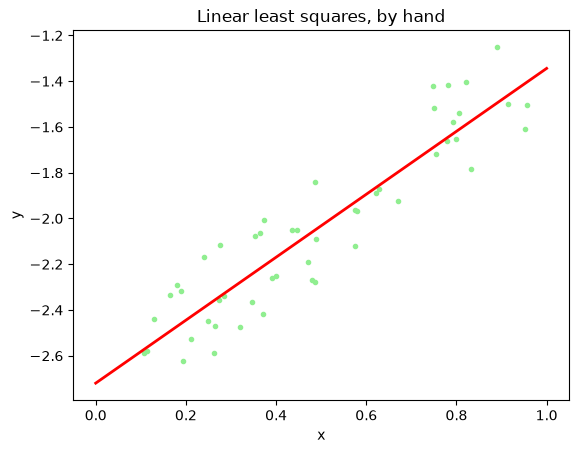

theta: [ 1.37569543 -2.71981614]
LLS from scipy stats time: 0.0005599999999998939


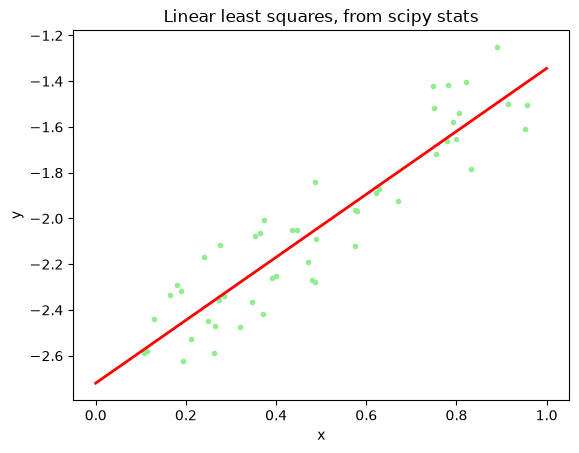

In [10]:
lf = LinearLatentFunction()
size = 50
batch = lf.get_batch(size)
model = LinearModel(size)

start = time.process_time()
x = np.array(batch.x_data)
y = np.array(batch.y_data)
model.train(x, y)
print("theta:", model.theta)
print("LLS time:", time.process_time() - start)
model.plot(x, y, "Linear least squares, by hand")

start = time.process_time()
model.train_from_stats(x, y)
print("theta:", model.theta)
print("LLS from scipy stats time:", time.process_time() - start)
model.plot(x, y, "Linear least squares, from scipy stats")

### Ridge Regression

The ridge regression (or regularized least squares, or Tikhonov regularization) method finds the best linear model from a batch of data, but ensuring that the obtained weights are not too high, using

$$ \boldsymbol{\theta}^* = \min_{\boldsymbol{\theta}} \underbrace{[\frac{\lambda}{2}||\boldsymbol{\theta}||^2 + \frac{1}{2}\|{\bf y}-\boldsymbol{\theta}^\intercal\bar{\bf X}\|^2]}_{L(\boldsymbol{\theta})}.$$

The parameters for the optimal model are given by:

$$ \boldsymbol{\theta}^* = (\lambda \boldsymbol{I} + \bar{\bf X}^\intercal\bar{\bf X})^{-1}{\bar{\bf X}}^\intercal{\bf y}.$$

In the Line class above, fill the `train_regularized(self, x_data, y_data, coef)` function.

And check that it works with a new batch of data

theta regularized: [ 0.29307357 -1.4720004 ]
regularized LLS : 0.0007129999999999637


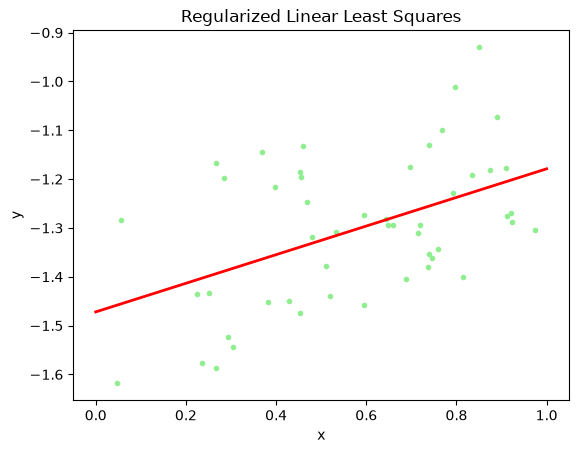

In [11]:
# We use the same batch as before, uncomment if you want to use another batch
lf = LinearLatentFunction()
size = 50
batch = lf.get_batch(size)
model = LinearModel(size)

start = time.process_time()
model.train_regularized(batch.x_data, batch.y_data, coef=0.01)
print("theta regularized:", model.theta)
print("regularized LLS :", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "Regularized Linear Least Squares")



## Study part: linear least squares

### Key study: impact of regularization

For a batch of 50 points, study with the` train_regularized(self,x_data,y_data,coef)` function 
how the residuals degrade as you increase the value of ```coef``` in some well chosen range. 
Explain what you see. A good idea would be to make a picture with coef in the x axis and the residuals in the y axis, 
and then to comment it. Having a look at the learned model may also help.

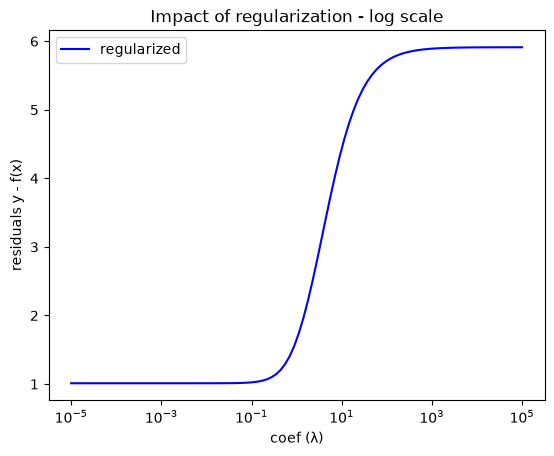

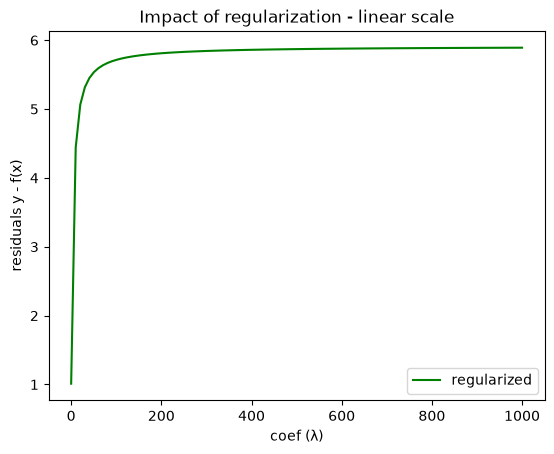

In [12]:
lf = LinearLatentFunction()
batch = lf.get_batch(50)
x = np.array(batch.x_data)
y = verti_to_horiz(np.array(batch.y_data))   # y piatto, per sicurezza
model = LinearModel(50)


coefs = np.logspace(-5, 5, 100)   # 100 values from 0.001 to 1000


errors = []                    
for c in coefs:
    model.train_regularized(x, y, c)
    errors.append(model.compute_error(x, y))

plt.plot(coefs, errors, color='blue', label='regularized')
plt.xscale('log')
plt.xlabel("coef (λ)")
plt.ylabel("residuals y - f(x)")
plt.title("Impact of regularization - log scale")
plt.legend()
plt.show()



coefs_lin = np.linspace(0, 1000, 100)   

errors_lin = []
for c in coefs_lin:
    model.train_regularized(x, y, c)
    errors_lin.append(model.compute_error(x, y))

plt.plot(coefs_lin, errors_lin, color='green', label='regularized')
plt.xlabel("coef (λ)")
plt.ylabel("residuals y - f(x)")
plt.title("Impact of regularization - linear scale")
plt.legend()
plt.show()


# For small values of lambda, the error is the same as the least squares error:
# lambda is little compared to X^T X, so theta is the least squares solution.
# This is the minimum possible error, so regularization can only make it higher.
# When lambda increases, the error becomes higher, because lambda forces theta towards zero.
# For very large lambda, theta is almost zero, so the model becomes the line y = 0
# and the error becomes y, the distance between the points and zero.
# The error stops increasing because theta cannot go below zero, so the curve
# reaches a plateau (like an asymptote).


### Optional study: comparing your LLS code and train_from_stats

Does your ```train(self, x_data, y_data)``` function provide exactly the same results 
as the ```train_from_stats(self, x_data, y_data)``` function?
Call both functions 1000 times with batches containing between 5000 and 50.000 data points and compare their run time with a figure.
Explain what you see.

size 5000
  theta (our code):   [ 1.80087453 -1.93705328]
  theta (scipy):      [ 1.80087453 -1.93705328]
  max difference:     1.3322676295501878e-15
size 10000
  theta (our code):   [ 1.79285677 -1.93219786]
  theta (scipy):      [ 1.79285677 -1.93219786]
  max difference:     8.659739592076221e-15
size 20000
  theta (our code):   [ 1.80884405 -1.9401079 ]
  theta (scipy):      [ 1.80884405 -1.9401079 ]
  max difference:     3.219646771412954e-14
size 50000
  theta (our code):   [ 1.79726918 -1.93491629]
  theta (scipy):      [ 1.79726918 -1.93491629]
  max difference:     2.886579864025407e-15


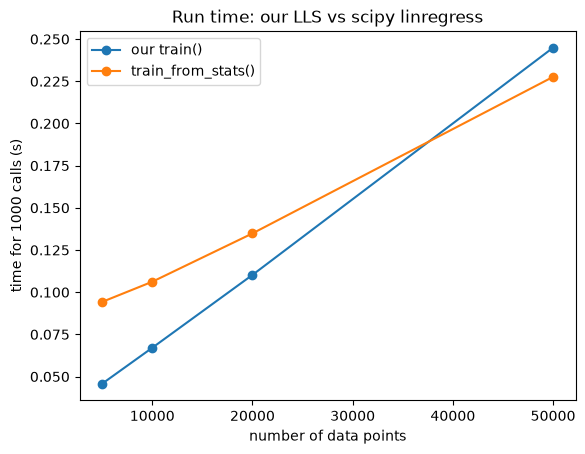

In [13]:
# Optional study:

lf = LinearLatentFunction()
sizes = [5000, 10000, 20000, 50000]  
n_calls = 1000                       
times_hand, times_stats = [], []

for size in sizes:
    batch = lf.get_batch(size)
    x = np.array(batch.x_data)
    y = np.array(batch.y_data)

    # Our least squares implementation 
    model_hand = LinearModel(size)
    start = time.process_time()
    for _ in range(n_calls):
        model_hand.train(x, y)
    times_hand.append(time.process_time() - start)

    # scipy implementation
    model_stats = LinearModel(size)
    start = time.process_time()
    for _ in range(n_calls):
        model_stats.train_from_stats(x, y)
    times_stats.append(time.process_time() - start)

    print("size", size)
    print("  theta (our code):  ", model_hand.theta)
    print("  theta (scipy):     ", model_stats.theta)
    print("  max difference:    ", np.max(np.abs(model_hand.theta - model_stats.theta)))

plt.plot(sizes, times_hand, 'o-', label="our train()")
plt.plot(sizes, times_stats, 'o-', label="train_from_stats()")
plt.xlabel("number of data points"); plt.ylabel("time for " + str(n_calls) + " calls (s)")
plt.title("Run time: our LLS vs scipy linregress")
plt.legend()
plt.show()

# Comment:
# Results: the two functions give the same parameters up to tiny differences.
# They are not exactly identical, because they compute
# the solution in different ways,so rounding errors of floating-point numbers accumulate differently.
# These differences are negligible and grow slightly with the number of points.

# Run time: for both methods the time grows roughly linearly with the number of
# points, since every point must be processed. Our implementation is faster for
# small batches, while scipy is faster for large ones. scipy has a higher fixed
# cost per call, but a lower cost per point.
# Our code builds a new matrix X_bar and computes matrix products at each call,
# so its cost grows faster with the data. In any case both are very fast




# Radial Basis Function Networks

## Coding part

Let us now code Radial Basis Function Networks (RBFNs). 
We implement several regression techniques with these models: batch least squares, 
gradient descent, and recursive least squares. 
We first define a general purpose RBFN class that encodes the vector of parameters $\theta$, 
the function $\phi(x)$, a function to compute the error of a model and a plotting function.

In [15]:
color_map = ["yellow","brown","orange","green","cyan","pink","red","blue","black","violet"]

class RBFN(Gaussians):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.theta = np.zeros(self.nb_features)

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of input variables
        :param x: A vector of input variables of size N
        :return: A vector of function approximator outputs with size the number of x datapoints
        """
        f = np.dot(self.phi_output(x).transpose(), self.theta)
        return f

    def feature(self, x, idx):
        """
        Get the output of the idx^th feature for a given input vector
        This is function f() considering only one feature
        Used mainly for plotting the features

        :param x: A vector of dependent variables of size N
        :param idx: index of the feature

        :return: the value of the feature for x
        """
        phi = self.phi_output(x)
        return phi[idx] * self.theta[idx]

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
        """
        Compute the residuals (squared sum of errors) over all the dataset
        :param x_data: the x values of datapoint
        :param y_data: the y values of datapoint

        :return: the residuals of the data given the model
        """
        error = np.linalg.norm(y_data - self.f(x_data))
        return error

    # ------ Plot function -------#
    def plot(self, x_data, y_data, title):
        """
        Given a dataset x_data, y_data, plots the points of the dataset, 
        the feature functions multiplied by their weight parameter 
        and the resulting model of the latent function
        :param x_data: the x values of datapoint
        :param y_data: the y values of datapoint

        :return: nothing
        """
        size = 500
        xs = np.linspace(0.0, 1.0, size)
        z = []
        for i in xs:
            z.append(self.f(np.array([i])))

        z2 = []
        for i in range(self.nb_features):
            temp = []
            for j in xs:
                temp.append(self.feature(np.array([j]), i))
            z2.append(temp)
            plt.plot(xs, z2[i], color=color_map[i%10])
        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=3, color='red')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

### Batch RBFNs

When applied to RBFNs, there are two perspectives about the batch least squares method.

#### First perspective

The **first perspective** considers that the RBFN is used to project from an input space into a feature space, 
before performing the standard linear least square calculation in this projected space.

Thus, from the batch of data we build the Gram matrix ${\bf G}$, projecting each datapoint $(x_i)_{1 \leq i \leq N}$ 
into its output vector for all the features $(\phi_j({\bf x}_i))_{1 \leq j \leq E}$. 
Then we apply the standard linear least square method, replacing the augmented design matrix $\bar{\bf X}$ with the Gram matrix ${\bf G}$:

$$  \boldsymbol{\theta}^* = ({\bf G}^\intercal{\bf G})^{-1}{{\bf G}}^\intercal{\bf y}.$$

This is the easiest approach to code in python.

In the code of the ```BatchRBFN1``` class below, fill the ```train_ls(self, x_data, y_data)``` function.

In [16]:
class BatchRBFN1(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # ------ batch least squares first perspective) ---------
    def train(self, x_data, y_data):
        
        G = self.phi_output(x_data).T
        y_data = verti_to_horiz(y_data) 
        
        self.theta = np.linalg.inv(G.T@G)@G.T@y_data



#### Second perspective

In the **second perspective**, we perform the whole calculation from scratch. We want to minimize the following error:
$$\epsilon(\boldsymbol{\theta}) = \frac{1}{2N}\sum_{i=1}^N (y_i - f_{\boldsymbol{\theta}}({\bf x}_i))^2.$$

To get a local minimum over $\boldsymbol{\theta}$ of the function $\epsilon(\boldsymbol{\theta})$, 
we need to solve $\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = {\bf 0}$.
To compute the gradient, we use $\nabla (g^2) = 2g\nabla g$. Therefore, we have

$$\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N  \left(y_i - f_{\boldsymbol{\theta}}\big( {\bf x}_i\big)\right)\nabla_\boldsymbol{\theta} f_{\boldsymbol{\theta}}({\bf x}_i).$$

Since $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, 
we have $\nabla_\boldsymbol{\theta} f_{\boldsymbol{\theta}}({\bf x}_i) = \phi({\bf x}_i)$ and we get

$$\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N  \left(y_i - \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right)\phi({\bf x}_i)$$

To make the gradient $\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = {\bf 0}$, we get:

$$\frac{1}{N}\sum_{i=1}^N \left(y_i - \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right)\phi({\bf x}_i) = 0$$

$$\frac{1}{N}\sum_{i=1}^N \left(\phi({\bf x}_i)y_i - \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right) = 0$$

$$\left( \sum_{i=1}^N \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \right) \boldsymbol{\theta} = \sum_{i=1}^N \phi({\bf x}_i) y_i.$$

Let us set

$${\bf A} = \left( \sum_{i=1}^N \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \right)$$

and $${\bf b} = \sum_{i=1}^N \phi({\bf x}_i) y_i.$$

We then have ${\bf A} \boldsymbol{\theta} = {\bf b}$.

${\bf A}$ is not necessarily an invertible matrix, and the general solution is obtained as $\boldsymbol{\theta} = A^\sharp b$, 
by using either the ``pseudo-inverse'' $A^\sharp$ ```(np.linalg.pinv(A))``` or using ```theta = np.linalg.solve(A,b)```.

In the ```BatchRBFN2``` class below, fill the code of the ```train(self, x_data, y_data)``` function according to the above perspective.

In [17]:
class BatchRBFN2(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # ------ batch least squares (second perspective) ---------
    def train(self, x_data, y_data):

        A = np.zeros((self.nb_features,self.nb_features))
        b = np.zeros(self.nb_features)
        phi = self.phi_output(x_data)

        for i in range(phi.shape[1]):
            A += np.outer(phi[:,i],phi[:,i])
            b += phi[:,i]*y_data[i]

        self.theta = np.linalg.solve(A,b)


Now, run the code below to see if yours works.

theta ls1 : [ 0.10912431 -0.01016087  0.02197345  0.12025938  0.31695235  0.45693912
 -0.79856812 -0.26781725 -0.8052684  -0.18965961]
error :  0.43088154860994693
RBFN LS time: 0.0024660000000000792


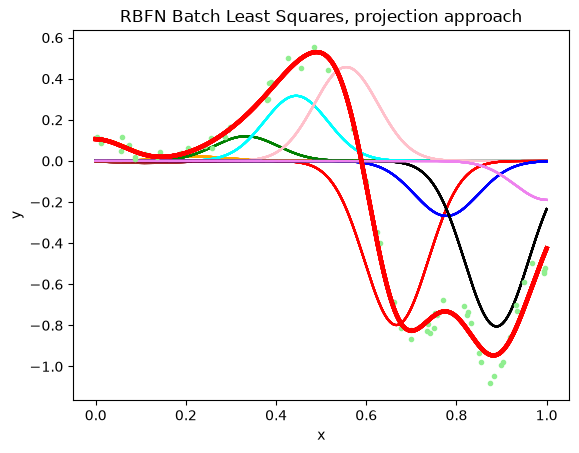

theta ls2 : [ 0.10912431 -0.01016087  0.02197345  0.12025938  0.31695235  0.45693912
 -0.79856812 -0.26781725 -0.8052684  -0.18965961]
error :  0.4308815486099469
RBFN LS2 time: 0.0005889999999997286


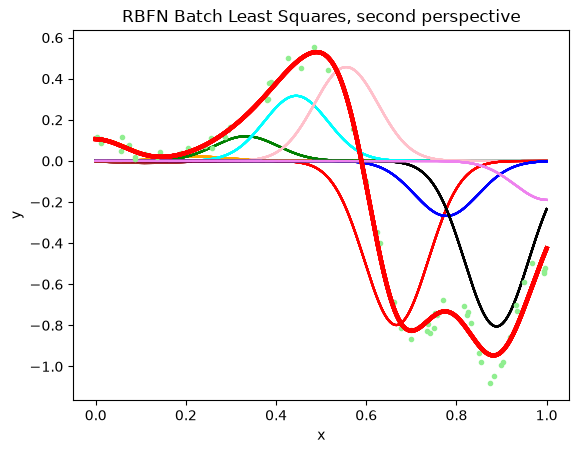

In [18]:
lf = NonLinearLatentFunction()
size = 60
batch = lf.get_batch(size)
model = BatchRBFN1(nb_features=10)

start = time.process_time()
model.train(batch.x_data, batch.y_data)
error = model.compute_error(batch.x_data, batch.y_data)
print("theta ls1 :", model.theta)
print("error : ", error)
print("RBFN LS time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Batch Least Squares, projection approach")

model = BatchRBFN2(nb_features=10)
start = time.process_time()
model.train(batch.x_data, batch.y_data)
error = model.compute_error(batch.x_data, batch.y_data)
print("theta ls2 :", model.theta)
print("error : ", error)
print("RBFN LS2 time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Batch Least Squares, second perspective")

##  Incremental RBFNs

For this part we define a general purpose IncrRBFN class that we derive below in different subclasses to implement the various algorithms.

In [19]:
class IncrRBFN(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.theta = np.random.random(self.nb_features)
        print(self.theta)

    def f(self, x, theta=None):
        """
        Get the output of the function approximator for a given vector of input variables 
    
        :param x: A vector of dependent variables of size N
        :param theta: A vector of coefficients to apply to the features. 
        :If left blank the method will default to using the trained thetas in self.theta.
        
        :return: A vector of function approximator outputs with size nb_features
        """
        if not hasattr(theta, "__len__"):
            theta = self.theta
        value = np.dot(self.phi_output(x).transpose(), theta)
        return value

    # -------- this function will be redefined in subclasses -----------------
    def train(self, x, y, alpha):
        raise NotImplementedError

### Gradient Descent

Let the vector $\boldsymbol{\theta}^{(t)}$ be the value of the parameters of the regression model at iteration $t$. 
We observe some new data $({\bf x}^{(t+1)}, y^{(t+1)})$.
The error of the current model on this pair is
$$\epsilon^{(t+1)} = y^{(t+1)} - f_{\boldsymbol{\theta}}( {\bf x}^{(t+1)}).$$

The idea of gradient descent is to slightly modify $\boldsymbol{\theta}$ to decrease $\epsilon^{(t+1)}$.

To do so, we consider the function $\boldsymbol{\theta} \mapsto y^{(t+1)} - f_{\boldsymbol{\theta}}\left( {\bf x}^{(t+1)}\right)$ and compute its gradient in $\boldsymbol{\theta}^{(t+1)}$, which we denote by $\nabla_\boldsymbol{\theta}^{(t+1)}$.

Since we have $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, 
we get $\nabla_\boldsymbol{\theta}^{(t+1)} = - \phi({\bf x}^{(t+1)})$.

The gradient of a function is oriented towards the direction of steepest increase. 
This means that it gives the direction in which a small modification of the vector 
of inputs leads to the largest increase of the function output. 
The opposite direction is the one of steepest decrease.

Here, the goal is to decrease $\epsilon^{(t+1)}$ thus $\boldsymbol{\theta}^{(t+1)}$ should be modified 
in the direction defined by $- \nabla_{\boldsymbol{\theta}}^{(t+1)} =  \phi({\bf x}^{(t+1)})$.
The resulting update formula is

\begin{align*}
 \boldsymbol{\theta}^{(t+1)} &= \boldsymbol{\theta}^{(t)} + \alpha \epsilon^{(t+1)} \nabla_{\boldsymbol{\theta}}^{(t+1)} \\
 &= \boldsymbol{\theta}^{(t)} + \alpha (y^{(t+1)} - f_{\boldsymbol{\theta}}( {\bf x}^{(t+1)})) \phi({\bf x}^{(t+1)})^\intercal \\
\end{align*}

where $\alpha > 0$ is a coefficient called the ``learning rate''.

Using $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, we can also write it:
$$\boldsymbol{\theta}^{(t+1)} = \boldsymbol{\theta}^{(t)} + \alpha (y^{(t+1)} - \phi({\bf x}^{(t+1)})^\intercal \boldsymbol{\theta}^{(t)}) \phi({\bf x}^{(t+1)})^\intercal.$$

### Relationship to training neural networks

The approach above is at the heart of machine learning techniques used to tune neural networks. 
The error $\epsilon^{(t+1)}$ is called the **loss function**. 
We have seen that we could slightly decrease this error for next time by descending 
the gradient of this loss with respect to the model parameters $\theta$. 
In neural networks libraries such as pytorch or tensorflow, we do the same: 
we compute a loss corresponding to the error made by the model on some data, 
and the library will perform gradient descent with respect to the parameters by computing the derivative for you.

In the GDRBFN class below, fill the `train(self, x, y, alpha)` function.

In [20]:
class GDRBFN(IncrRBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # -------- gradient descent -----------------
    def train(self, x, y, alpha):

        phi = verti_to_horiz(self.phi_output(x))
        error = y - self.f(x)
        self.theta = self.theta + alpha * error * phi
       


And check that it works

[0.72451751 0.94593388 0.89155589 0.87799558 0.93843588 0.53382022
 0.90219005 0.12712141 0.901401   0.7344413 ]
error :  0.5334795764135046
RBFN grad descent time: 0.01908299999999974


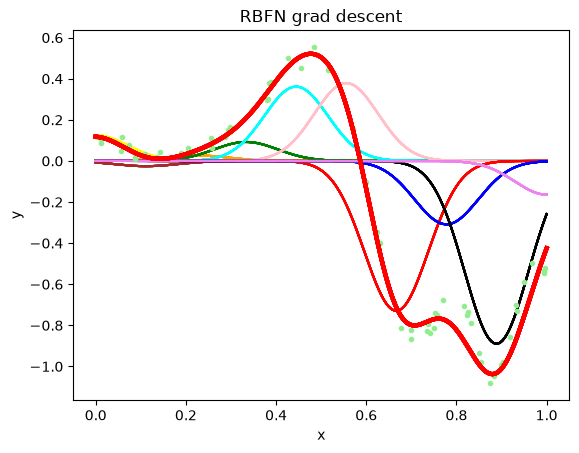

In [21]:
# We use the same batch as before, uncomment if you want to use another batch
# lf = NonLinearLatentFunction()
# size = 500
# batch = lf.get_batch(size)
max_iter = 500
model = GDRBFN(nb_features=10)
start = time.process_time()

for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train(x, y, alpha=0.5)

error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN grad descent time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN grad descent")

### Recursive Least Squares

Recursive Least Squares is the incremental version of the batch Least Squares method.
In this variant, ${\bf A}$ and ${\bf b}$ are recomputed everytime some new data pair is obtained, with the following equations: 

\begin{align*}
{\bf A}^{(t+1)} &= {\bf A}^{(t)} + \phi({\bf x}^{(t+1)}) \phi({\bf x}^{(t+1)})^\intercal,\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t+1)}) y^{(t+1)}.
\end{align*}

The parameters are then computed as $\boldsymbol{\theta}^{(t+1)} = {\bf A}^{(t+1)\sharp} b^{(t+1)}$.
One may also use ```numpy.linalg.solve(A,b)``` as before, but this can fail when ${\bf A}$ is singular.

Another incremental approach avoids the computation of the pseudo-inverse ${\bf A}^{(t+1)\sharp}$ 
by computing this inverse incrementally, using the Sherman-Morrison formula: 

\begin{align*}
  u = v^T &= \phi({\bf x}^{(t)}) \\
{\bf A}^{(t+1)\sharp} &= {\bf A}^{(t)\sharp} - \frac{{\bf A}^{(t)\sharp} uv {\bf A}^{(t)\sharp}}{1 + v {\bf A}^{(t)\sharp} u},\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t)}).\\
\end{align*}

**Remark:** to apply this formula, we must start with a non-zero value for $A^{(0)\sharp}$, e.g. the Identity matrix.

In the RLSRBFN class below, fill the code of the `train(self, x, y)` function. 
The one with the Sherman-Morrisson approach is provided.

### Recursive Least Squares

Recursive Least Squares is the incremental version of the batch Least Squares method.
In this variant, ${\bf A}$ and ${\bf b}$ are recomputed everytime some new data pair is obtained, with the following equations: 

\begin{align*}
{\bf A}^{(t+1)} &= {\bf A}^{(t)} + \phi({\bf x}^{(t+1)}) \phi({\bf x}^{(t+1)})^\intercal,\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t+1)}) y^{(t+1)}.
\end{align*}

The parameters are then computed as $\boldsymbol{\theta}^{(t+1)} = {\bf A}^{(t+1)\sharp} b^{(t+1)}$.
One may also use ```numpy.linalg.solve(A,b)``` as before, but this can fail when ${\bf A}$ is singular.

Another incremental approach avoids the computation of the pseudo-inverse ${\bf A}^{(t+1)\sharp}$ 
by computing this inverse incrementally, using the Sherman-Morrison formula: 

\begin{align*}
  u = v^T &= \phi({\bf x}^{(t)}) \\
{\bf A}^{(t+1)\sharp} &= {\bf A}^{(t)\sharp} - \frac{{\bf A}^{(t)\sharp} uv {\bf A}^{(t)\sharp}}{1 + v {\bf A}^{(t)\sharp} u},\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t)}).\\
\end{align*}

**Remark:** to apply this formula, we must start with a non-zero value for $A^{(0)\sharp}$, e.g. the Identity matrix.

In the RLSRBFN class below, fill the code of the `train(self, x, y)` function. 
The one with the Sherman-Morrisson approach is provided.

In [22]:
class RLSRBFN(IncrRBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.a = np.zeros(shape=(self.nb_features, self.nb_features))
        self.b = np.zeros(self.nb_features)
        self.a_inv = np.matrix(np.identity(self.nb_features))
    
    # -------- recursive least squares -----------------
    def train(self, x, y):
        
        phi = verti_to_horiz(self.phi_output(x))
        self.a += np.outer(phi, phi.T)
        self.b += phi *y
        self.theta = np.linalg.pinv(self.a) @ self.b

  
    # -------- recursive least squares with Sherman-Morrison -----------------
    def train_rls_sherman_morrison(self, x, y):
        u = self.phi_output(x)
        v = self.phi_output(x).transpose()
        mat = v * self.a_inv * u

        value = mat[0, 0] + 1
        if value == 0: # If it's not invertible
          print("Non invertible matrix")
          return None
        coef = 1.0 / value

        prod = np.dot(u, v)

        tmp_mat = np.dot(self.a_inv, prod) 
        tmp_mat2 = np.dot(tmp_mat, self.a_inv)

        self.a_inv = self.a_inv - coef * tmp_mat2

        tmp_vec = y * verti_to_horiz(self.phi_output(x))
        self.b = self.b + tmp_vec

        # Very surprisingly, we get a [[1 2 3 4]] vec here instead of [1 2 3 4]
        result = np.dot(self.a_inv, self.b)
        # And even more surprisingly we have to write this so that it works
        self.theta = np.array(result)[0]

Finally, run them:

[0.14260254 0.69354433 0.08590783 0.51883742 0.73502812 0.03454201
 0.9339363  0.40508647 0.64540451 0.59502186]
RLS theta [ 0.10886939 -0.01045059  0.02189016  0.12059386  0.31724027  0.45474867
 -0.79778625 -0.26539577 -0.80781937 -0.19049559]
error :  0.4310041484340891
RBFN RLS time: 0.1455510000000002


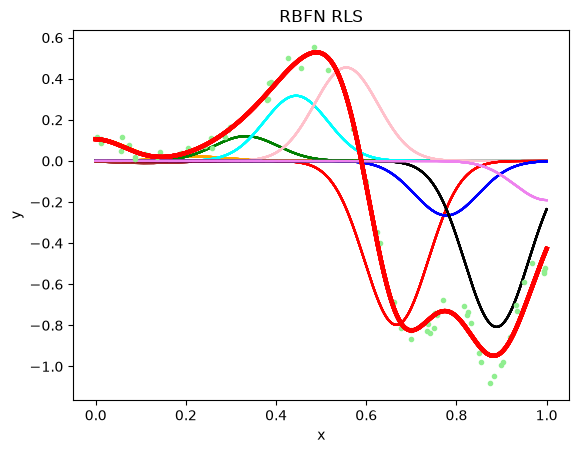

[0.8296562  0.5056745  0.51997761 0.31465316 0.19882571 0.75000416
 0.36372374 0.31007224 0.69361165 0.69717057]
RLS SM theta [ 0.10911414 -0.00949697  0.02156582  0.11884512  0.31996663  0.44677329
 -0.78897161 -0.27970214 -0.79335572 -0.20040181]
error :  0.4315432334174218
RBFN  Sherman-Morrisson time: 0.0840209999999999


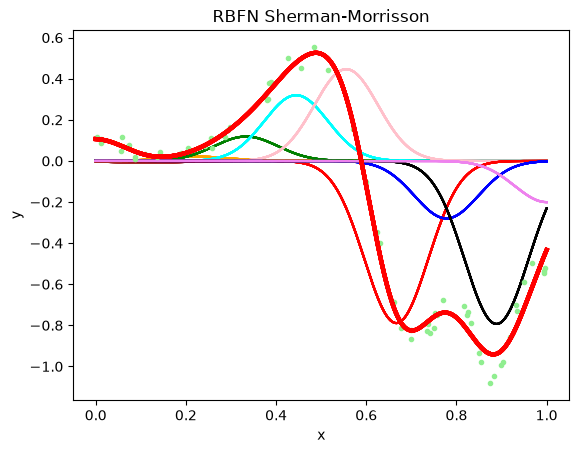

In [23]:
# We use the same batch as before, uncomment if you want to use another batch
# lf = NonLinearLatentFunction()
# size = 500
# batch = lf.get_batch(size)
max_iter = 5000
model = RLSRBFN(nb_features=10)
start = time.process_time()

for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train(x, y)

print ("RLS theta", model.theta)
error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN RLS time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN RLS")

# Need to reinit the model as model.theta must be random again
model = RLSRBFN(nb_features=10)
start = time.process_time()
for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train_rls_sherman_morrison(x, y)

print ("RLS SM theta", model.theta)
error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN  Sherman-Morrisson time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Sherman-Morrisson")

## Study part: batch RBFNs

 ### Key study: influence of the number of features

Study the evolution of the error as a function of the number of features, from 2 to 60. 
A good idea would be to make a picture with the number of features in the x axis and the residuals in the y axis, 
and then to comment it. Have a look at the model when the number of features is large (e.g. 60). What is happening?

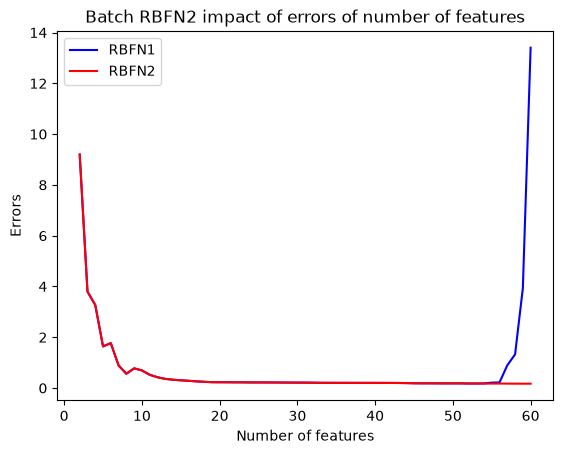

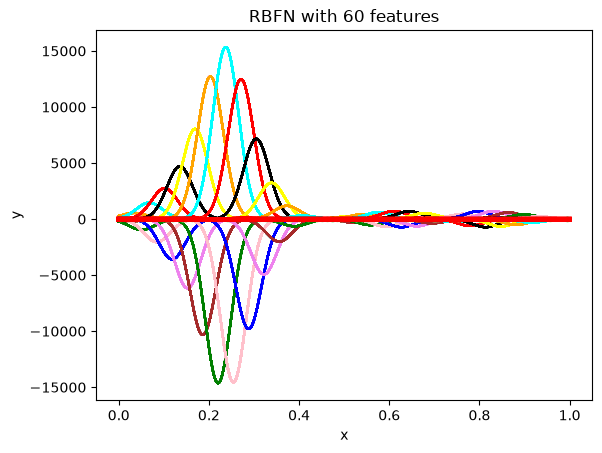

In [24]:
# STUDY PART: Batch RBFN

lf = NonLinearLatentFunction()
batch = lf.get_batch(100)
x = np.array(batch.x_data)
y = verti_to_horiz(np.array(batch.y_data))   


errors1, errors2, n_features = [],[],[]                     
for n in range(2,61):
    model1 = BatchRBFN1(nb_features=n)
    model1.train(x,y)
    error1 = model1.compute_error(batch.x_data, batch.y_data)
    errors1.append(error1)
    n_features.append(n)

    model2 = BatchRBFN2(nb_features=n)
    model2.train(x,y)
    error2 = model2.compute_error(batch.x_data, batch.y_data)
    errors2.append(error2)

plt.plot(n_features, errors1, color='blue', label="RBFN1")
plt.plot(n_features, errors2, color='red', label="RBFN2")

plt.xlabel("Number of features"); plt.ylabel("Errors")
plt.title("Batch RBFN2 impact of errors of number of features");
plt.legend()
plt.show()

model = BatchRBFN2(nb_features=60)
model.train(x, y)
model.plot(batch.x_data, batch.y_data, "RBFN with 60 features")


# Comment:
# The error decreases as the number of features increases, up to about
# 20 features; after that, adding features does not improve the result.
# The error does not reach zero because of the noise in the data: no model
# can predict the noise, so there is a minimum error that cannot be removed.
#
# The two curves overlap: the two perspectives are equivalent, because they
# solve the same least squares problem with the same matrix A = G^T G and vector b.
# Around 60 features, however, model 2 keeps its precision while model 1 does not.
# This is because G^T G becomes almost singular (the Gaussians overlap a lot):
# model 1 computes the inverse with np.linalg.inv, which is numerically unstable
# in this case, while model 2 uses np.linalg.solve, which is more stable.
#
# With 60 features the weights of the Gaussians explode, but they balance and
# cancel each other, because G^T G is close to singular. The training error is
# low, but this does not mean that the model is good. To avoid this problem,
# we could add the lambda parameter, using regularized (ridge) regression.

### Optional study: comparing both perspectives

Calling the train functions at least 1000 times, comment on the difference in computation time between the first and the second perspective.

first perspective : 0.04553200000000146 s
second perspective: 0.11768 s
second/ first: 2.58455591671783
first perspective : 0.03857900000000036 s
second perspective: 0.20068400000000075 s
second/ first: 5.201897405324111
first perspective : 0.06116099999999847 s
second perspective: 0.391788 s
second/ first: 6.405846863197296
first perspective : 0.11010699999999929 s
second perspective: 0.975816 s
second/ first: 8.862433814380614


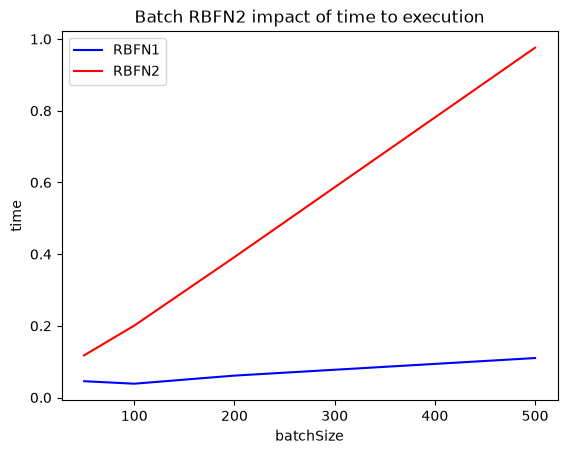

first perspective : 0.037231000000000236 s
second perspective: 0.2020149999999994 s
second/ first: 5.425989095108863


In [31]:
# Optional Study part: comparing both perspective

n = 1000

lf = NonLinearLatentFunction()
batchSize = [50, 100, 200, 500]
timeT1, timeT2 = [], []

for i in range(len(batchSize)):
    batch = lf.get_batch(batchSize[i])
    
    start1 = time.process_time()
    for _ in range(n):
        model = BatchRBFN1(nb_features=10)
        model.train(batch.x_data, batch.y_data)
    time1 = time.process_time() - start1
    timeT1.append(time1)
    
    # 
    start2 = time.process_time()
    for _ in range(n):
        model2 = BatchRBFN2(nb_features=10)
        model2.train(batch.x_data, batch.y_data)
    time2 = time.process_time() - start2
    timeT2.append(time2)
    
    print("first perspective :", time1, "s")
    print("second perspective:", time2, "s")
    print("second/ first:", time2/ time1) 

plt.plot(batchSize, timeT1, color='blue', label="RBFN1")
plt.plot(batchSize, timeT2, color='red', label="RBFN2")

plt.xlabel("batchSize"); plt.ylabel("time")
plt.title("Batch RBFN2 impact of time to execution");
plt.legend()
plt.show()


# Comment:
# RBFN1 (first perspective) is faster than RBFN2 (second perspective), because
# it does everything with a few operations on whole matrices, which numpy runs
# in optimized code. The second perspective uses a Python for loop and adds one
# term at each iteration. 
# Each iteration has a fixed cost, so repeating it for
# every data point takes much more time. The result is the same, only the
# computation time changes.


## Study part: incremental RBFNs

### Key study: Incremental versus Batch

By comparing their computation time and error with a growing number of features, 
comment on the main differences between incremental and batch methods with RBFNs. 
What are their main advantages and disadvantages? 
Explain how you would choose between an incremental and a batch method, depending on the context.

[0.04261015 0.05292206 0.57655879 0.98489351 0.4492907 ]
[0.35582245 0.08078788 0.66070469 0.35149824 0.39898133]
[0.17848896 0.8686749  0.52020927 0.96939539 0.02741144 0.73688565
 0.4194408  0.78360578 0.90176968 0.89977232]
[0.00264626 0.22575789 0.72846609 0.5360406  0.94352887 0.15322164
 0.92915757 0.24947421 0.86616337 0.7530665 ]
[0.57926477 0.06624545 0.42119042 0.96336909 0.41904123 0.1096597
 0.38658165 0.75565719 0.71666664 0.65566453 0.31060852 0.12473684
 0.05818518 0.33320587 0.19130434 0.44879206 0.02476664 0.3397168
 0.69443467 0.72220969]
[0.50149495 0.95237795 0.46995215 0.88854151 0.78882314 0.09150075
 0.71176633 0.14393355 0.16948975 0.02304369 0.25897818 0.43998842
 0.2401088  0.73888051 0.2691297  0.91129146 0.87756496 0.85101237
 0.80988856 0.6046674 ]
[0.46453337 0.74332264 0.86145643 0.22387463 0.35490908 0.49523511
 0.73161784 0.3082767  0.65027829 0.98689141 0.11390778 0.19800022
 0.39291978 0.46500824 0.0597332  0.55492107 0.322513   0.48015834
 0.79949411

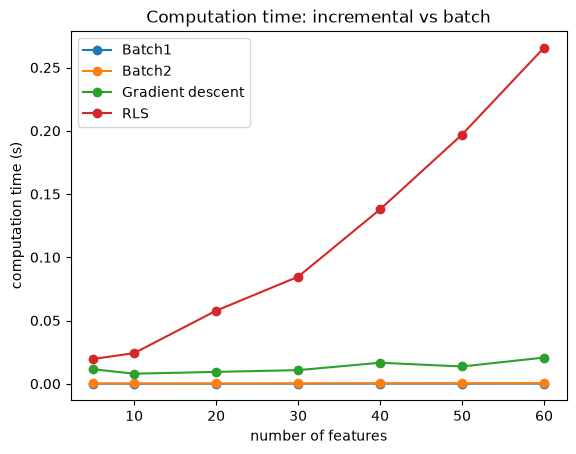

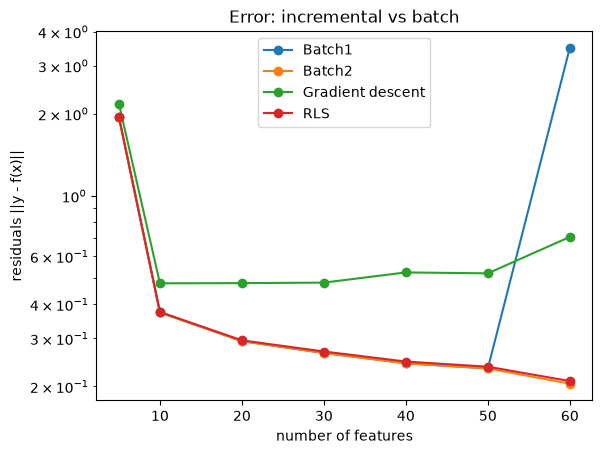

In [26]:
# STUDY PART: Incremental RBFN

batch = lf.get_batch(100)
x = np.array(batch.x_data)
y = verti_to_horiz(batch.y_data)
features_list = [5, 10, 20, 30, 40, 50, 60]
max_iter = 1000         

times_batch, times_batch1, times_gd, times_rls = [], [], [], []
errors_batch, errors_batch1, errors_gd, errors_rls = [], [], [], []

for nb in features_list:

    # Batch1
    model1 = BatchRBFN1(nb)
    start1 = time.process_time()
    model1.train(x, y)
    times_batch1.append(time.process_time() - start1)
    errors_batch1.append(model1.compute_error(x, y))
    
    # Batch2
    model = BatchRBFN2(nb)
    start = time.process_time()
    model.train(x, y)
    times_batch.append(time.process_time() - start)
    errors_batch.append(model.compute_error(x, y))
    
    # Gradient
    model = GDRBFN(nb)
    start = time.process_time()
    for _ in range(max_iter):
        xi, yi = batch.get_random_sample()
        model.train(xi, yi, alpha=0.5)
    times_gd.append(time.process_time() - start)
    errors_gd.append(model.compute_error(x, y))

    # RLS 
    model = RLSRBFN(nb)
    start = time.process_time()
    for _ in range(max_iter):
        xi, yi = batch.get_random_sample()
        model.train(xi, yi)
    times_rls.append(time.process_time() - start)
    errors_rls.append(model.compute_error(x, y))

# Grafico tempo
plt.plot(features_list, times_batch1, 'o-', label='Batch1')
plt.plot(features_list, times_batch, 'o-', label='Batch2')
plt.plot(features_list, times_gd, 'o-', label='Gradient descent')
plt.plot(features_list, times_rls, 'o-', label='RLS')
plt.xlabel("number of features")
plt.ylabel("computation time (s)")
plt.title("Computation time: incremental vs batch")
plt.legend()
plt.show()

# Grafico 2: errore
plt.plot(features_list, errors_batch1, 'o-', label='Batch1')
plt.plot(features_list, errors_batch, 'o-', label='Batch2')
plt.plot(features_list, errors_gd, 'o-', label='Gradient descent')
plt.plot(features_list, errors_rls, 'o-', label='RLS')
plt.yscale('log')
plt.xlabel("number of features")
plt.ylabel("residuals ||y - f(x)||")
plt.title("Error: incremental vs batch")
plt.legend()
plt.show()

# # Time:
# Batch methods are the fastest (one single computation with all the data).
# Gradient descent has a low and almost constant cost per step.
# RLS becomes slower when the number of features grows (it solves a features x features system at each step).

# Error:
# Batch2 and RLS give the same exact least squares solution.
# Batch1 explodes above 30 features because inv is numerically unstable.
# Gradient descent has a higher error: it only approaches the optimum and depends
# on the learning rate and the number of iterations.

# Conclusion:
# Batch methods are better when all the data are available and the model is small.
# Incremental methods are better when the data arrive one by one or are too many:
# RLS for precision with few features, gradient descent for models with many parameters.

### Optional study 1: comparing recursive variants

By varying the number of features, the number of samples and the amount of noise in the data generator, 
compare the different incremental variants (gradient descent and RLS with and without the Sherman-Morrison formula). 
Which is the most precise? The fastest? Using graphical displays where you are varying the above parameters is strongly encouraged. 
To change the amount of noise in the generated data, 
look in the [latent_function.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/latent_function.py) file.

[0.24802043 0.93195699 0.14046871 0.98682202 0.8546426 ]
[0.09855834 0.60060101 0.29303076 0.88390849 0.24887005]
[0.2672375  0.2302151  0.74593053 0.79578078 0.80814299]
[0.67512784 0.16607842 0.51718075 0.88987896 0.91093328 0.16851617
 0.41190221 0.27135363 0.16565647 0.90023175]
[0.96085843 0.86848971 0.75860609 0.25449228 0.53617331 0.60573055
 0.93782035 0.6946578  0.31926515 0.66809119]
[0.37155609 0.52905156 0.29721792 0.45527688 0.06688518 0.22817845
 0.02409996 0.58860445 0.5258182  0.00406839]
[0.15178364 0.67526121 0.15160133 0.70320359 0.32417913 0.30091129
 0.98903457 0.53429847 0.66805627 0.22654124 0.96164941 0.10350789
 0.66323615 0.77509111 0.2954752  0.04561442 0.80556363 0.0475113
 0.85259212 0.14628314]
[0.43636989 0.94494232 0.91829454 0.84224823 0.93210794 0.63943486
 0.71952888 0.99389321 0.7157407  0.83262926 0.87898597 0.74227953
 0.03259209 0.67626122 0.18541009 0.84361551 0.38160367 0.82054793
 0.31368421 0.49666079]
[0.79315826 0.21375882 0.35195653 0.29464

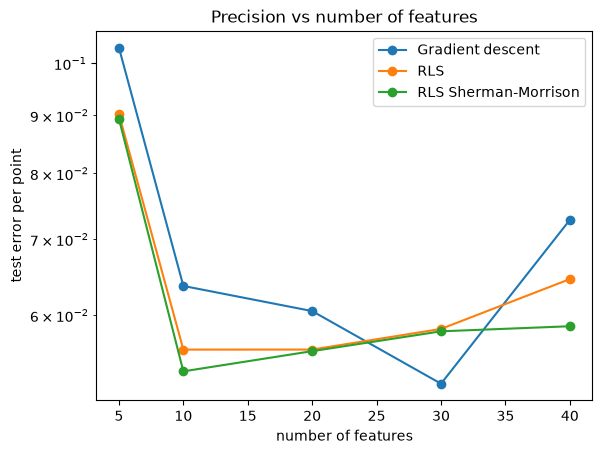

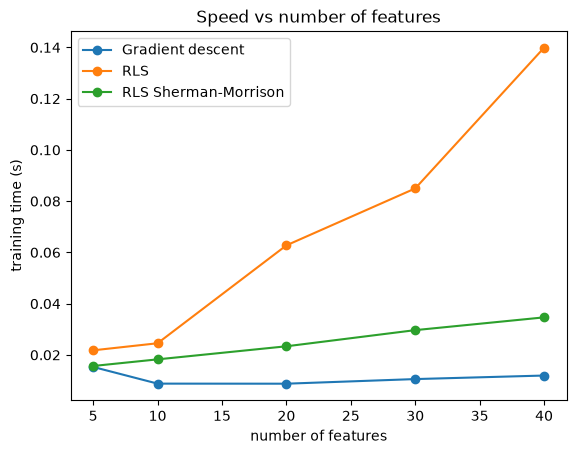

[0.79867126 0.6527341  0.02695188 0.3756952  0.9887259  0.01873923
 0.89892558 0.40241695 0.27468194 0.2996684 ]
[0.20104875 0.93786703 0.66468399 0.70477113 0.95740627 0.21261046
 0.7721206  0.19088306 0.48228005 0.62935508]
[0.11140515 0.05399871 0.14336757 0.62506122 0.84946264 0.32263139
 0.38019822 0.14923079 0.29977898 0.32587304]
[0.46903844 0.37939026 0.64035559 0.2023372  0.66176151 0.13169215
 0.06648187 0.51865176 0.26603293 0.11629207]
[0.51891181 0.29113183 0.27095323 0.65156259 0.16129191 0.48813595
 0.05390511 0.9239507  0.574361   0.28456331]
[0.21593411 0.2293291  0.47433017 0.59771394 0.31793721 0.70617287
 0.98512645 0.57794681 0.91122348 0.3482973 ]
[0.27174258 0.41286868 0.08688579 0.01671015 0.27063537 0.17812296
 0.48051855 0.50241661 0.10985846 0.83819579]
[0.76758158 0.99142071 0.15919812 0.46343936 0.72559045 0.47122065
 0.25356376 0.65333821 0.97520388 0.0375441 ]
[0.4298582  0.02098251 0.61313378 0.9705143  0.77044919 0.22149755
 0.95428975 0.30008413 0.6299

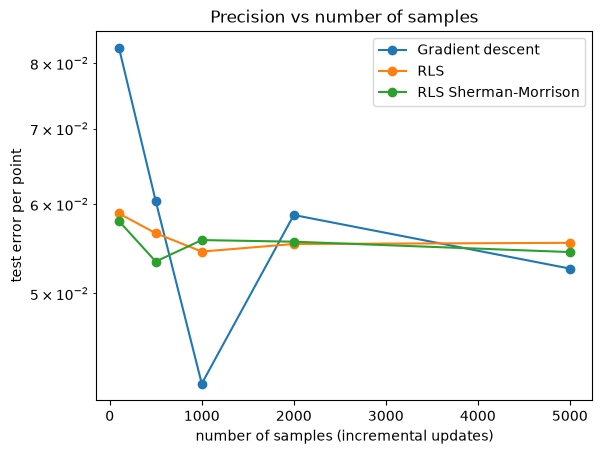

[0.5369131  0.05644944 0.56359686 0.84585792 0.35146971 0.09474819
 0.19891815 0.02590626 0.64272754 0.81759393]
[0.97246477 0.52200478 0.1011627  0.37309519 0.76844772 0.15754663
 0.22501138 0.33123068 0.81304533 0.45452345]
[0.56777322 0.82823137 0.28395405 0.17598744 0.18661353 0.73049341
 0.00992179 0.98852576 0.56217594 0.1235402 ]
[0.17484427 0.70537101 0.68015475 0.77990764 0.42978754 0.75410893
 0.99410411 0.45725198 0.26720313 0.83268974]
[0.93759988 0.58767457 0.94328368 0.70300609 0.25255261 0.05686664
 0.57606553 0.50283963 0.56426462 0.3307068 ]
[0.51357189 0.97233473 0.37796896 0.97866207 0.86687706 0.34467183
 0.79925457 0.75295497 0.18138517 0.60934921]
[0.66871609 0.82332642 0.48309623 0.99119604 0.81184332 0.53334423
 0.10688101 0.099461   0.6800253  0.13304467]
[0.22033217 0.79000499 0.11873056 0.04224085 0.13264378 0.91795266
 0.33215941 0.99721833 0.089198   0.09487561]
[0.35201373 0.16507667 0.43594505 0.42716665 0.48039967 0.24161128
 0.30489592 0.26913252 0.7362

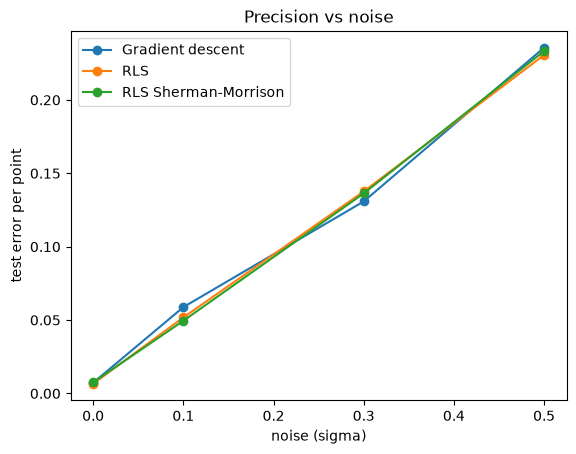

In [27]:
# Optional study 1: comparing recursive variants

alpha = 0.5
lf = NonLinearLatentFunction()

# Test batch WITHOUT noise
lf.sigma = 0
N_test = 500
test_batch = lf.get_batch(N_test)

# Impact of the number of features
lf.sigma = 0.1
batch = lf.get_batch(100)
max_iter = 1000
features_list = [5, 10, 20, 30, 40]
errors_gd, errors_rls, errors_sm = [], [], []
times_gd, times_rls, times_sm = [], [], []

for nb in features_list:
    # Gradient descent
    model = GDRBFN(nb)
    start = time.process_time()
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha)
    times_gd.append(time.process_time() - start)
    errors_gd.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    # RLS 
    model = RLSRBFN(nb)
    start = time.process_time()
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y)
    times_rls.append(time.process_time() - start)
    errors_rls.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    # RLS with Sherman-Morrison
    model = RLSRBFN(nb)
    start = time.process_time()
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train_rls_sherman_morrison(x, y)
    times_sm.append(time.process_time() - start)
    errors_sm.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(features_list, errors_gd, 'o-', label="Gradient descent")
plt.plot(features_list, errors_rls, 'o-', label="RLS")
plt.plot(features_list, errors_sm, 'o-', label="RLS Sherman-Morrison")
plt.yscale('log')
plt.xlabel("number of features"); plt.ylabel("test error per point")
plt.title("Precision vs number of features")
plt.legend()
plt.show()

plt.plot(features_list, times_gd, 'o-', label="Gradient descent")
plt.plot(features_list, times_rls, 'o-', label="RLS")
plt.plot(features_list, times_sm, 'o-', label="RLS Sherman-Morrison")
plt.xlabel("number of features"); plt.ylabel("training time (s)")
plt.title("Speed vs number of features")
plt.legend()
plt.show()

# Impact of the number of samples
nb = 10
iters_list = [100, 500, 1000, 2000, 5000]
errors_gd, errors_rls, errors_sm = [], [], []

for max_iter in iters_list:
    model = GDRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha)
    errors_gd.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = RLSRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y)
    errors_rls.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = RLSRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train_rls_sherman_morrison(x, y)
    errors_sm.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(iters_list, errors_gd, 'o-', label="Gradient descent")
plt.plot(iters_list, errors_rls, 'o-', label="RLS")
plt.plot(iters_list, errors_sm, 'o-', label="RLS Sherman-Morrison")
plt.yscale('log')
plt.xlabel("number of samples (incremental updates)"); plt.ylabel("test error per point")
plt.title("Precision vs number of samples")
plt.legend()
plt.show()

# Impact of noise 
nb = 10
max_iter = 1000
sigmas = [0, 0.1, 0.3, 0.5]
errors_gd, errors_rls, errors_sm = [], [], []

for s in sigmas:
    lf.sigma = s
    batch = lf.get_batch(100)

    model = GDRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha)
    errors_gd.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = RLSRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y)
    errors_rls.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = RLSRBFN(nb)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train_rls_sherman_morrison(x, y)
    errors_sm.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(sigmas, errors_gd, 'o-', label="Gradient descent")
plt.plot(sigmas, errors_rls, 'o-', label="RLS")
plt.plot(sigmas, errors_sm, 'o-', label="RLS Sherman-Morrison")
plt.xlabel("noise (sigma)"); plt.ylabel("test error per point")
plt.title("Precision vs noise")
plt.legend()
plt.show()


# Comment:
# The error is measured on a noise-free test set, so it shows how close each model
# gets to the true latent function, not how well it fits the training samples.
#
# Precision: RLS and RLS with Sherman-Morrison give almost the same error, because
# both converge to the least-squares solution. Sherman-Morrison can be slightly
# different with few samples, since it starts from A^-1 = I, which acts like a small
# ridge regularization. Gradient descent is the least precise: it approaches the
# solution with small steps and does not reach it exactly in the given budget.
#
# Speed: gradient descent is the fastest, since each update is a simple vector
# operation. Sherman-Morrison is faster than RLS, and the gap grows with the number
# of features n: RLS computes a pseudo-inverse at each step (cost ~ n^3), while
# Sherman-Morrison only updates the inverse (cost ~ n^2).
#
# Samples and noise: the RLS variants reach their final error after only a few
# hundred samples, while gradient descent needs many more. For all methods, the
# error increases with the noise, since the models partly fit the noise of the
# training samples.

### Optional study 2: Studying overfitting

From the same dataset, generate two batches, a training batch on which your model is trained
and a validation batch which is used to determine when incremental regression starts overfitting
Plot training and validation error curves, and conclude on the right number of iterations to avoid overfitting

[0.38319848 0.7978561  0.45770552 0.75275506 0.54187017 0.46773442
 0.65242599 0.81624285 0.50517427 0.49089149 0.20792388 0.85216936
 0.38421373 0.20495708 0.21196576 0.75603018 0.26136254 0.04013532
 0.85372604 0.09610412 0.19639886 0.60842827 0.52103558 0.7550026
 0.14257186 0.98475519 0.28088559 0.22146727 0.0988693  0.1918245
 0.78830267 0.09419408 0.47430085 0.71849699 0.69469365 0.37728014
 0.29545945 0.50544638 0.90535308 0.5898984 ]
Best number of iterations (validation): 6800
Validation error at the best point: 0.18930031978844727
Validation error at the end: 0.22278200936286227


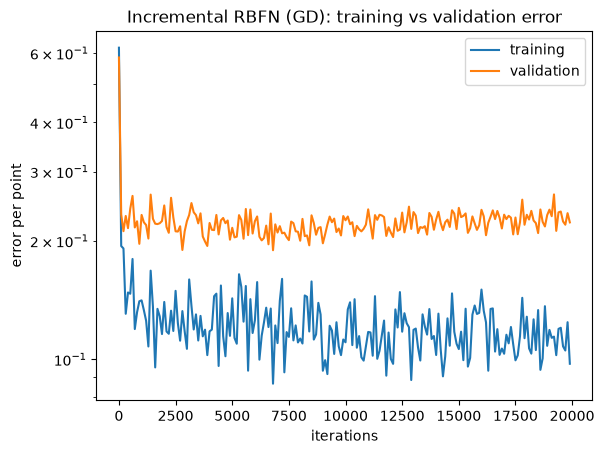

In [32]:
# Optional study 2

lf = NonLinearLatentFunction()
lf.sigma = 0.5                    
N_train = 30                     
N_val = 200                      
train_batch = lf.get_batch(N_train)
val_batch = lf.get_batch(N_val)

model = GDRBFN(40)                
alpha = 0.5
max_iter = 20000

iters, train_err, val_err = [], [], []
for t in range(max_iter):
    x, y = train_batch.get_random_sample()     
    model.train(x, y, alpha)
    if t % 100 == 0:                           
        iters.append(t)
        train_err.append(model.compute_error(train_batch.x_data, train_batch.y_data) / np.sqrt(N_train))
        val_err.append(model.compute_error(val_batch.x_data, val_batch.y_data) / np.sqrt(N_val))

best = np.argmin(val_err)
print("Best number of iterations (validation):", iters[best])
print("Validation error at the best point:", val_err[best])
print("Validation error at the end:", val_err[len(val_err) - 1])

plt.plot(iters, train_err, label="training")
plt.plot(iters, val_err, label="validation")
plt.yscale('log')
plt.xlabel("iterations"); plt.ylabel("error per point")
plt.title("Incremental RBFN (GD): training vs validation error")
plt.legend()
plt.show()

# Comment:
# At the beginning both errors drop quickly, because the model learns the general
# shape of the function. Then the validation error reaches a minimum and starts to
# grow, while the training error stays low. This is overfitting: with 40 features
# and only 30 noisy points, the model learns the noise instead of the real function.
# The best number of iterations is where the validation error is minimal, so we
# should stop the training there (early stopping).
# The curves oscillate because each update uses only one sample with a large
# learning rate (alpha = 0.5). A smaller alpha would give smoother curves.

## Iterative regression with RBFNs

Iterative regression is between batch regression and incremental regression: as in incremental regression, regression is performed iteratively but as in batch regression, we use the full batch of samples at each iteration. Sampling a small subset of the batch (a mini-batch) would correspond to stochastic gradient descent (SGD) whereas standard incremental regression just takes one sample at each iteration.

We do not study iterative regression within this lab, but trying to do it on your own is a valuable exercise.

# Locally Weighted Regression

Another family of models is Locally Weighted Least Squares (LWLS).
The LWLS algorithm uses a weighted sum of $M$ local linear models.
For each local model $\boldsymbol{\theta}_k$, the size of the vector $\boldsymbol{\theta}_k$ 
is the number of dimensions of $\bar{\bf x}$ to take the intercept 
into account (remember that $\bar{\bf x} = ( x_1 \ x_2 \cdots x_d \ 1)^\intercal$ as defined in the provided code 
with the ```bar(x)``` function.
Thus $\dim (\boldsymbol{\theta}_k) = \dim ({\bf x}) +1 = d + 1$.

The model of the global latent function can be written

$$f({\bf x}) = \sum_{k=1}^{M}  \frac{\phi_k({\bf x}). m_{\boldsymbol{\theta}_k}({\bf x})}{\sum_{j=1}^{M} \phi_j({\bf x})},$$

with $m_{\boldsymbol{\theta}_k}({\bf x}) = \bar{\bf x}^\intercal \boldsymbol{\theta}_k $ and where $M$ is the number of models.

Each local model $\boldsymbol{\theta}_k$ is optimized by minimizing the following locally weighted error from $N$ datapoints:

$$\epsilon_k(\boldsymbol{\theta}_k) = \frac{1}{2N}\sum_{i=1}^N \phi_k({\bf x}_i)\left(y_i - m_{\boldsymbol{\theta}_k}({\bf x}_i)\right)^2$$

$$= \frac{1}{2N}\sum_{i=1}^N \phi_k( {\bf x}_i) \left(y_i- (\bar{\bf x}_i)^\intercal .\boldsymbol{\theta}_{i} \right)^2.$$

As with the least squares method, we try to cancel out the gradient, which amounts to solving:

$$-\frac{1}{N}\sum_{i=1}^N \phi_k({\bf x}_i)\bar{\bf x}_i \left(y_i - (\bar{\bf x}_i)^\intercal .\boldsymbol{\theta}_k \right) = 0.$$

Therefore, we pose $\boldsymbol{\theta}_k = {\bf A}^\sharp_k {\bf b}_k$, with: 
$${\bf A}_k = \sum_{i=1}^N \phi_k({\bf x}_i). \bar{\bf x}_i^\intercal. (\bar{\bf x}_i)$$
$${\bf b}_k = \sum_{i=1}^N \phi_k({\bf x}_i). \bar{\bf x}_i^\intercal. y_i.$$

This calculation gives us the parameters $\boldsymbol{\theta}_k$ of each local linear model. 
The global parameter $\boldsymbol{\theta}$ is now a matrix resulting from the concatenation of all local models $\boldsymbol{\theta}_k$.

## Coding part

The code corresponding to the LWR method is available in the ```LWR``` class below. 

**In this code, you have to fill the ```train(self, x_data, y_data)``` function**

In [29]:
class LWR(Gaussians):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        # The first dimension is 2 because we assume the input is one-dimensional
        # So we just have two parameters per receptive field
        self.theta = np.zeros((2, self.nb_features))

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of datapoints
        :param x: a single vector of N datapoints (each datapoint being of dimension d=1)
        :returns: a vector of N function approximator outputs
        """
        weights = self.phi_output(x).T # B x E
        lin_model = bar_design(x) @ self.theta  # B x 2 @ 2 x E = B x E
        weighted_sum = (lin_model * weights).sum(-1) # tensor product
        sum_weights = weights.sum(-1)
        return weighted_sum / sum_weights
      
    def feature(self, x, idx):
        """
         Get the output of the idx^th feature for a given input variable(s)
         :param x: a single or vector of dependent variables with size [d] for which to calculate the features
         :param idx: index of the feature
         :returns: a vector of values
         """
        return np.dot(bar_design(x), self.theta[:, idx])

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
      return np.linalg.norm(y_data - self.f(x_data))

    # ----------------------#
    # # Training Algorithm ##
    # ----------------------#

    def train(self, x_data, y_data) -> None:
        """
        Locally weighted least square function
        This code is specific to the 1D case
        :param x_data: a vector of x values
        :param y_data: a vector of y values
        :return: nothing (set the self.theta vector)
        """
        for k in range(self.nb_features):
            A = np.zeros((2, 2))
            b = np.zeros((2, 1))

            nb_points = x_data.shape[0]
            for i in range(nb_points):

                x_i = x_data[i].reshape(1, x_data.shape[1])
                y_i = y_data[i]

                phi = self.phi_output(x_i)

                x_bar = bar_design(x_i)        
                w = phi[k, 0]                  
                A += w * (x_bar.T @ x_bar)     
                b += w * x_bar.T * y_i         

            result = np.dot(np.linalg.pinv(A), b)
            for i in range(2):
                self.theta[i, k] = result[i, 0]


    def plot(self, x_data, y_data, title):
        xs = np.linspace(0.0, 1.0, 1000)
        z = []
        for i in xs:
            val = self.f(np.array([[i]]))
            z.append(val)


        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=2, color='red')
        for i in range(self.nb_features):
            ww = (1.0 - 0.0) / self.nb_features / 2.
            xstmp = np.linspace(self.centers[i] - ww, self.centers[i] + ww, 100)

            z2 = []
            for j in xstmp:
                z2.append(self.feature(np.array([[j]]), i))
            plt.plot(xstmp, z2, lw=2, color='blue', ls='-')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

Once this is done, you can run the code:

LWR time: 0.010927000000000575


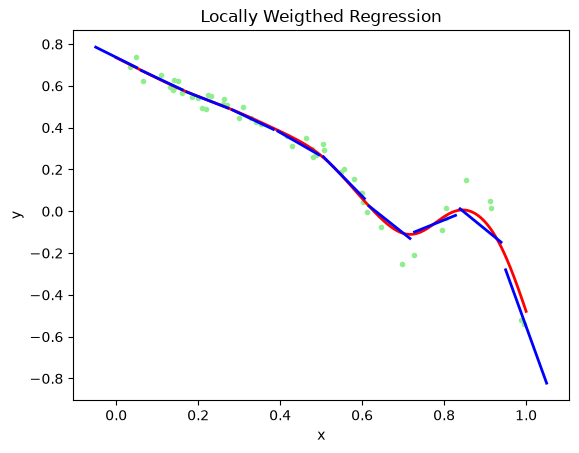

In [30]:
lf = NonLinearLatentFunction()
size = 50
batch = lf.get_batch(size)
model = LWR(nb_features=10)

start = time.process_time()
model.train(batch.x_data, batch.y_data)
print("LWR time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "Locally Weigthed Regression")

## Study part: LWR

### Key study: impact of the number of features

Study the impact of the number of features on the accuracy of LWR: make a drawing where you measure 
the residuals as a function of the number of features.

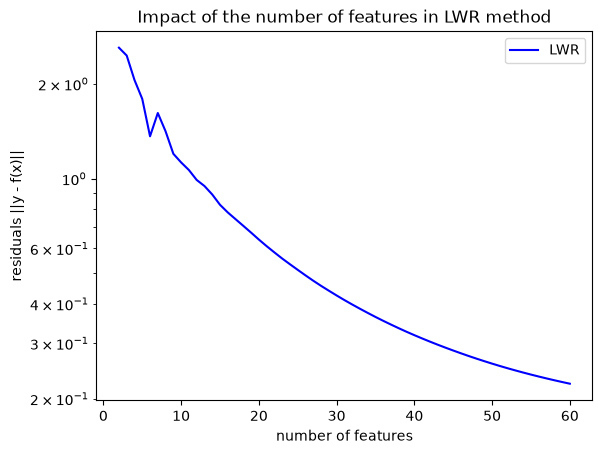

In [77]:
# Study part LWR

lf = NonLinearLatentFunction()
batch = lf.get_batch(50)
x = np.array(batch.x_data)
y = verti_to_horiz(np.array(batch.y_data))

features_list = range(2, 61)
errors_lwr = []

for nb in features_list:
    model = LWR(nb)
    model.train(x, y)
    errors_lwr.append(model.compute_error(x, y))
    
plt.plot(features_list, errors_lwr, color='blue', label='LWR')
plt.yscale('log')
plt.xlabel("number of features")
plt.ylabel("residuals ||y - f(x)||")
plt.title("Impact of the number of features in LWR method")
plt.legend()
plt.show()

# Comment
# Few features: high error, each local line covers a region where the function is not linear (underfitting).
# More features: smaller regions, the function is almost linear in each one, so the error decreases.
# Many features: each line fits very few points and the noise (overfitting),
# but no numerical explosion, since each local model only solves a stable 2x2 system.


### Optional study: regions with missing data

Introduce a filter that removes part of the data in some region of the x axis. Study how LWR behaves in regions where data is sparse.
the residuals as a function of the number of features.

# Regression with Neural Networks (in pytorch)

In this part we perform regression with neural networks.
We are using pytorch, which does for you a lot of what you have to code when using gradient descent with RBFNs.

All the code for performing regression is provided, you can focus on the study part.
The study below will focus on different training regimes.

In [78]:
!pip install torch

import torch as th
from torch import nn
from torch.nn import functional as func
from torch.utils.data import DataLoader
from torch.utils.data import Dataset

We use pytorch Dataset and DataLoader classes to facilitate data processing

In [79]:
class NonLinearRegressionData(Dataset):
    '''
    Custom 'Dataset' object for our regression data.
    Must implement these functions: __init__, __len__, and __getitem__.
    '''

    def __init__(self, x_data, y_data):
        self.x_data = th.from_numpy(x_data).float()
        self.y_data = th.from_numpy(y_data).float()

    def __len__(self):
        return(len(self.x_data))

    def __getitem__(self, idx):
        return(self.x_data[idx], self.y_data[idx])

Now, we define a neural network model.
It has the same $f()$ function as previous models, and the ```compute_error(x,y)``` function is also the same.
But now, the training function just calls ```update(loss)``` and gradient descent is performed using pytorch functions.

In [80]:
##################################################
## set up a multi-layer perceptron with PyTorch
##################################################

class NeuralNetwork(nn.Module):

  def __init__(self, l1, l2, l3, l4, out, learning_rate):
    super(NeuralNetwork, self).__init__()
    self.sigmoid = nn.Sigmoid() # not used in the default version
    self.relu = nn.ReLU()
    self.fc1 = nn.Linear(l1, l2)
    self.fc2 = nn.Linear(l2, l3)
    self.fc3 = nn.Linear(l3, l4)
    self.fc4 = nn.Linear(l4, out)
    self.optimizer = th.optim.Adam(self.parameters(), lr=learning_rate) # Here we could use different optimizers

  def forward(self, x):
      # x is assumed to be a tensor
      hidden1 = self.relu(self.fc1(x))
      hidden2 = self.relu(self.fc2(hidden1))
      hidden3 = self.relu(self.fc3(hidden2))
      output = self.fc4(hidden3)
      return output
  
  def compute_error(self, x_data, y_data):
    """
    Compute the residual error
    :param x_data: the x values of datapoint
    :param y_data: the y values of datapoint
    :return: the total residual error
    """
    x = (th.from_numpy(x_data).float())
    return np.linalg.norm(y_data - self.forward(x).detach().squeeze().numpy())

  def update(self, loss, retain_graph=False) -> None:
    """
    Apply a loss to a network using gradient backpropagation
    :param loss: the applied loss
    :return: nothing
    """
    self.optimizer.zero_grad()
    loss.backward(retain_graph=retain_graph)
    self.optimizer.step()

  def plot(self, x_data, y_data, title):
    """
    Given a dataset x_data, y_data, plots the points of the dataset (in green), 
    and the resulting model of the latent function (in red)
    :param x_data: the x values of datapoint
    :param y_data: the y values of datapoint
    :param title: a title for the figure
    :return: nothing
    """
    
    plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
      
    inputs = th.from_numpy(x_data).float()
    formatted_input = th.reshape(inputs, (len(inputs), 1))
    y_model = model.forward(formatted_input).detach().squeeze().numpy()
      
    plt.plot(x_data, y_model, 'o', markersize=4, color='red')

    size = 500
    xs = np.linspace(0.0, 1.0, size)
    txs = th.from_numpy(xs).float()
    ftxs = th.reshape(txs, (len(txs), 1))
    ys = model.forward(ftxs).detach().squeeze().numpy()
    plt.plot(xs, ys, lw=1, color='pink')

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.show()

### General data set-up

We store data into a pytorch dataset

In [81]:
# We use a non-linear batch of size 100
lf = NonLinearLatentFunction()
size = 100
batch = lf.get_batch(size)

# instantiate Dataset object for current training data
train_data = NonLinearRegressionData(batch.x_data, batch.y_data)

### Training loop

In [82]:
def train(max_iter, freq):
  current_loss = 0.0

  # Iterate for a number of training iterations
  for epoch in range(max_iter):
    # Iterate over the DataLoader for training data
    for _, data in enumerate(train_dataloader, 0):
      # Get inputs
      inputs, targets = data
      formatted_input = th.reshape(inputs, (len(inputs), 1))
      outputs = model(formatted_input).squeeze()
      # Compute loss
      loss = func.mse_loss(outputs, targets)
      # Perform optimization
      model.update(loss)
      # Print statistics
      current_loss += loss.item()

    if (epoch + 1) % freq == 0:
      print('Loss after iteration %5d: %.3f' %
            (epoch + 1, current_loss))
      current_loss = 0.0

### Batch, iterative version

We first train the network with a single batch of data.
We perform max_iter iterations to improve the network.

nb iterations 5000
Loss after iteration   250: 19.364
Loss after iteration   500: 3.257
Loss after iteration   750: 1.589
Loss after iteration  1000: 1.563
Loss after iteration  1250: 1.561
Loss after iteration  1500: 1.560
Loss after iteration  1750: 1.561
Loss after iteration  2000: 1.560
Loss after iteration  2250: 1.560
Loss after iteration  2500: 1.559
Loss after iteration  2750: 1.560
Loss after iteration  3000: 1.560
Loss after iteration  3250: 1.559
Loss after iteration  3500: 1.558
Loss after iteration  3750: 1.557
Loss after iteration  4000: 1.557
Loss after iteration  4250: 1.557
Loss after iteration  4500: 1.557
Loss after iteration  4750: 1.557
Loss after iteration  5000: 1.557
Batch training time: 1.2845240000000047
Global batch error: 0.7882677080592473


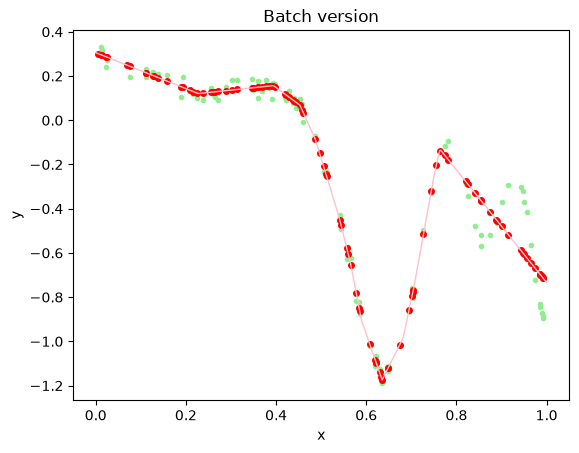

In [83]:
# Instantiate DataLoader
# We get a full size batch and shuffle the data
train_dataloader = DataLoader(train_data, batch_size=size, shuffle=True)

model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)

max_iter = 5000
print("nb iterations", max_iter)

start = time.process_time()
train(max_iter, 250)

print("Batch training time:", time.process_time() - start)
error = model.compute_error(batch.x_data, batch.y_data)
print("Global batch error:", error)
model.plot(batch.x_data, batch.y_data, "Batch version")

### Incremental version using minibatches

For getting minibatches, see the [get_minibatch()](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/batch.py) function.

nb iterations 5000
Loss after iteration   250: 92.118
Loss after iteration   500: 51.728
Loss after iteration   750: 47.246
Loss after iteration  1000: 43.170
Loss after iteration  1250: 20.375
Loss after iteration  1500: 8.058
Loss after iteration  1750: 6.905
Loss after iteration  2000: 6.690
Loss after iteration  2250: 6.604
Loss after iteration  2500: 6.571
Loss after iteration  2750: 6.561
Loss after iteration  3000: 6.560
Loss after iteration  3250: 6.560
Loss after iteration  3500: 6.552
Loss after iteration  3750: 6.553
Loss after iteration  4000: 6.556
Loss after iteration  4250: 6.555
Loss after iteration  4500: 6.551
Loss after iteration  4750: 6.547
Loss after iteration  5000: 6.553
Incremental mini-batch training time: 3.4135490000000033
Global batch error: 0.8064699529760188


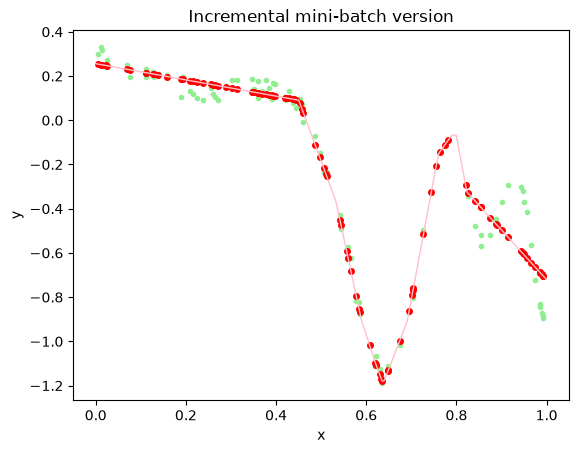

In [84]:
# Instantiate DataLoader
# We get mini_batches of size 25 and shuffle the data
train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=1e-3)

max_iter = 5000
print("nb iterations", max_iter)

start = time.process_time()
train(max_iter, 250)
print("Incremental mini-batch training time:", time.process_time() - start)
error = model.compute_error(batch.x_data, batch.y_data)
print("Global batch error:", error)
model.plot(batch.x_data, batch.y_data, "Incremental mini-batch version")

You can see that the batch version is a special case of the mini-batch version
where the size of the mini-batch is the size of the batch.

## Study part: neural networks

### Key study: comparisons between versions

Play with the dataset size. Once you have properly tuned the variants, study the evolution of the final error
and the training time depending on the size of the minibatch for a given budget of iterations.

Loss after iteration   500: 340.547
mini-batch 5 -> error: 1.6435129760134566  time: 1.477431000000001 s
Loss after iteration   500: 163.840
mini-batch 10 -> error: 1.6431210475250058  time: 0.7534380000000009 s
Loss after iteration   500: 79.728
mini-batch 25 -> error: 1.6258325884482974  time: 0.33565800000000046 s
Loss after iteration   500: 32.222
mini-batch 50 -> error: 1.6003844643784406  time: 0.19566000000000017 s
Loss after iteration   500: 30.724
mini-batch 100 -> error: 1.6692237157734755  time: 0.12644399999999933 s


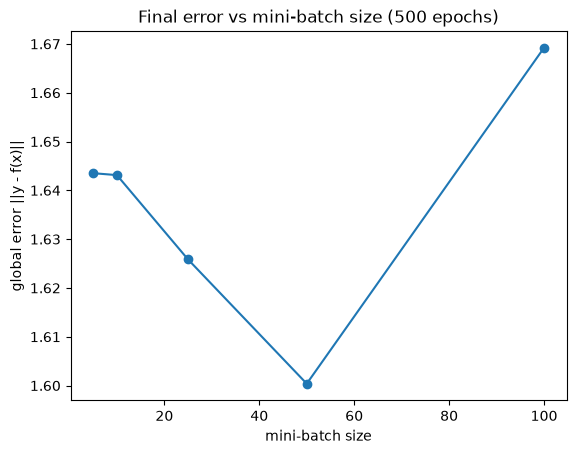

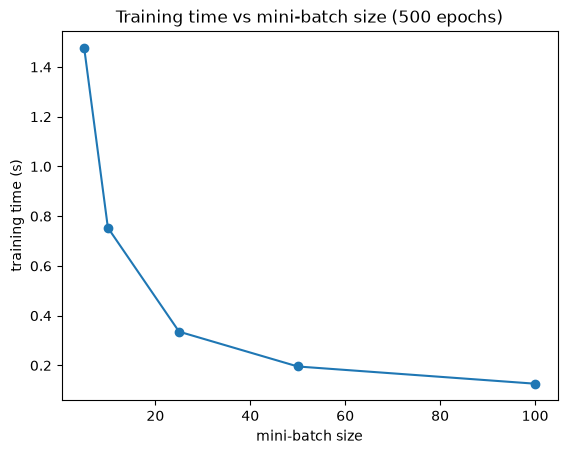

In [33]:
# This key study is expected for the lab

size = 100
lf = NonLinearLatentFunction()
batch = lf.get_batch(size)
train_data = NonLinearRegressionData(batch.x_data, batch.y_data)

# Parametri
max_iter = 500                             
batch_sizes = [5, 10, 25, 50, 100]
learning_rates = {5: 1e-3, 10: 1e-3, 25: 1e-3, 50: 3e-3, 100: 3e-3}

errors = []
times = []

for bs in batch_sizes:
    train_dataloader = DataLoader(train_data, batch_size=bs, shuffle=True)
    model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=learning_rates[bs])

    start = time.process_time()
    train(max_iter, max_iter)                  
    t = time.process_time() - start

    e = model.compute_error(batch.x_data, batch.y_data)
    print("mini-batch", bs, "-> error:", e, " time:", t, "s")
    errors.append(e)
    times.append(t)

# Grafico 1
plt.plot(batch_sizes, errors, 'o-')
plt.xlabel("mini-batch size")
plt.ylabel("global error ||y - f(x)||")
plt.title("Final error vs mini-batch size (" + str(max_iter) + " epochs)")
plt.show()

# Grafico 2
plt.plot(batch_sizes, times, 'o-')
plt.xlabel("mini-batch size")
plt.ylabel("training time (s)")
plt.title("Training time vs mini-batch size (" + str(max_iter) + " epochs)")
plt.show()

# Comment 
# # With a fixed number of epochs, small mini-batches perform more updates:
# lower error but much longer training time. Large mini-batches are faster,
# but with few updates the network may not converge.
# The error is not monotonic because the learning rate was not tuned for each size:
# with the same learning rate (5-25, 50-100) the error grows with the mini-batch size,
# and it drops when the learning rate increases (at 50). Random initialization also adds variability.
# So, to reach the minimum error, a good trade-off between learning rate and mini-batch size is needed

### Optional study 1: preventing overfitting

Distinguish training, validation and test batches, train the network until the validation loss stops decreasing, 
count the number of training epochs and measure the loss on the test batch.
By running a number of training epochs smaller and larger than the one found with the validation loss approach, 
study if this approach truly prevents overfitting. Showing the training loss and validation loss curves is higly recommended.

Training time: 2.3667049999999996
Best epoch (validation): 883
Validation error: 0.1568636395694098  Test error: 0.16431149741870868


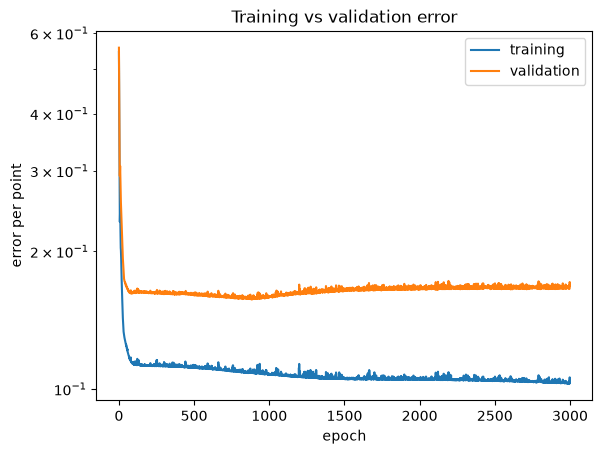

stop at epoch 221 -> test error: 0.16980985155682868
stop at epoch 442 -> test error: 0.1671568279122809
stop at epoch 883 -> test error: 0.16431149741870868
stop at epoch 1765 -> test error: 0.17350133684138594


In [36]:
# Optional study 1: preventing overfitting

# Batches
lf = NonLinearLatentFunction()
lf.sigma = 0.5                     

N_train, N_val, N_test = 30, 100, 100
train_batch = lf.get_batch(N_train)
val_batch   = lf.get_batch(N_val)
test_batch  = lf.get_batch(N_test)

# DataSet e DataLoader
train_data = NonLinearRegressionData(train_batch.x_data, train_batch.y_data)
train_dataloader = DataLoader(train_data, batch_size=10, shuffle=True)
model = NeuralNetwork(1, 64, 64, 64, 1, learning_rate=1e-3)

# Training every epoch
n_epochs = 3000
train_err, val_err, test_err = [], [], []

start = time.process_time()
for epoch in range(n_epochs):
    train(1, n_epochs)             # UNA epoca con la funzione train del prof
    train_err.append(model.compute_error(train_batch.x_data, train_batch.y_data) / np.sqrt(N_train))
    val_err.append(model.compute_error(val_batch.x_data, val_batch.y_data) / np.sqrt(N_val))
    test_err.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))
print("Training time:", time.process_time() - start)

# Best Epoch
best = np.argmin(val_err)
print("Best epoch (validation):", best + 1)
print("Validation error:", val_err[best], " Test error:", test_err[best])

# Training and validation functions
plt.plot(train_err, label="training")
plt.plot(val_err, label="validation")
plt.yscale('log')
plt.xlabel("epoch"); plt.ylabel("error per point")
plt.title("Training vs validation error")
plt.legend()
plt.show()

# Erorr tests
for e in [best // 4, best // 2, best, 2 * best, 4 * best]:
    if e < n_epochs:
        print("stop at epoch", e + 1, "-> test error:", test_err[e])

# Comment:
# The training error keeps decreasing during training, while the validation error
# reaches its minimum then slightly increases.
# The gap between the two curves shows overfitting: the network learns the noise
# of the 30 training points instead of the real function. In fact, the training
# error goes below the noise level.
# Early stopping works: the test error is lowest at the epoch chosen by the
# validation and higher if we stop earlier (underfitting)
# or later (overfitting).
# However, the validation curve is very noisy, so the chosen epoch is partly due
# to chance.


### Optional study 2: impact of the network architecture

Vary the activation functions, the number of layers and the number of neurons per layer and study the impact on regression error.

Loss after iteration  1000: 23.601
ReLU -> test error: 0.038842474906850916
Loss after iteration  1000: 43.682
Tanh -> test error: 0.033889344707272936
Loss after iteration  1000: 116.065
Sigmoid -> test error: 0.05512888844179847


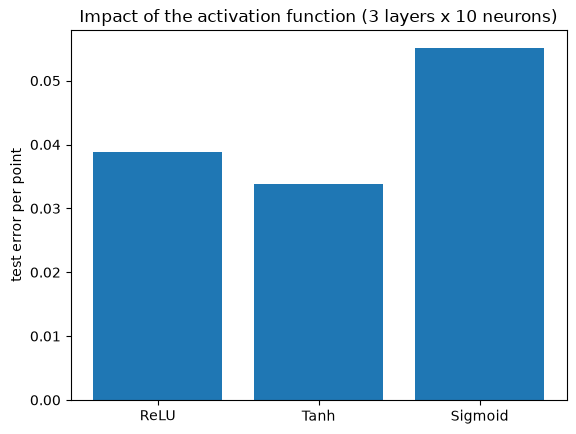

Loss after iteration  1000: 58.016
Loss after iteration  1000: 44.227
Loss after iteration  1000: 33.049


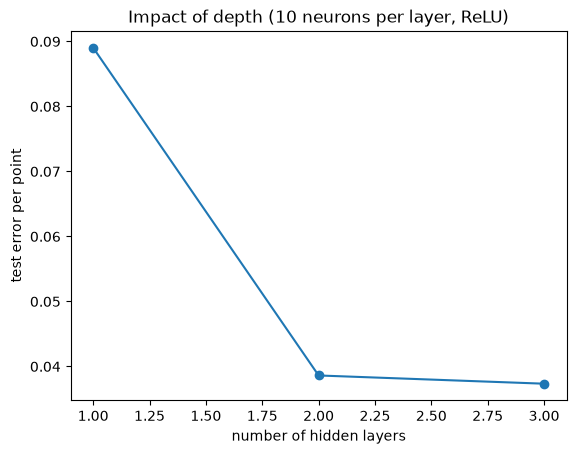

Loss after iteration  1000: 668.679
Loss after iteration  1000: 43.807
Loss after iteration  1000: 24.268
Loss after iteration  1000: 16.576
Loss after iteration  1000: 8.898
Loss after iteration  1000: 8.037


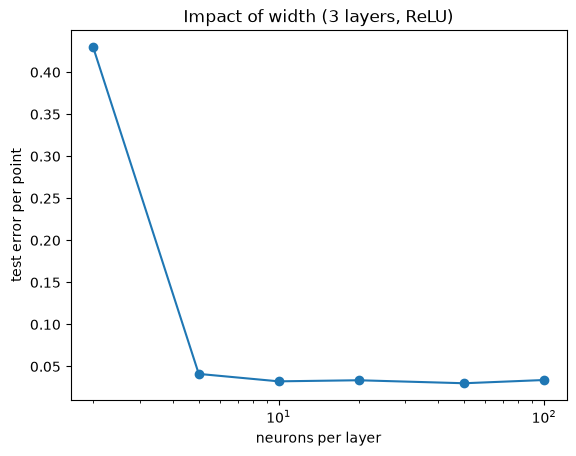

In [38]:
# Optional study 2: impact of the network architecture

class NeuralNetworkArch(NeuralNetwork):
    def __init__(self, width, n_layers, activation, learning_rate):
        super().__init__(1, width, width, width, 1, learning_rate)
        self.n_layers = n_layers          # quanti strati nascosti usare (1, 2 o 3)
        self.activation = activation      # es. nn.ReLU(), nn.Tanh(), nn.Sigmoid()

    def forward(self, x):
        h = self.activation(self.fc1(x))           # 1° strato nascosto (sempre)
        if self.n_layers >= 2:
            h = self.activation(self.fc2(h))       # 2° strato nascosto
        if self.n_layers >= 3:
            h = self.activation(self.fc3(h))       # 3° strato nascosto
        return self.fc4(h)                         # strato di uscita

# Data
lf = NonLinearLatentFunction()
N_train, N_test = 100, 200
train_batch = lf.get_batch(N_train)
test_batch = lf.get_batch(N_test)

train_data = NonLinearRegressionData(train_batch.x_data, train_batch.y_data)
train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
n_epochs = 1000

# Activation functions (3 strati da 10 neuroni)
activations = {"ReLU": nn.ReLU(), "Tanh": nn.Tanh(), "Sigmoid": nn.Sigmoid()}
act_errors = []
for name in activations:
    model = NeuralNetworkArch(10, 3, activations[name], learning_rate=3e-3)
    train(n_epochs, n_epochs)
    e = model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test)
    print(name, "-> test error:", e)
    act_errors.append(e)

plt.bar(list(activations.keys()), act_errors)
plt.ylabel("test error per point")
plt.title("Impact of the activation function (3 layers x 10 neurons)")
plt.show()

# Layers number
depths = [1, 2, 3]
depth_errors = []
for d in depths:
    model = NeuralNetworkArch(10, d, nn.ReLU(), learning_rate=3e-3)
    train(n_epochs, n_epochs)
    depth_errors.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(depths, depth_errors, 'o-')
plt.xlabel("number of hidden layers"); plt.ylabel("test error per point")
plt.title("Impact of depth (10 neurons per layer, ReLU)")
plt.show()

# Number or neurons (3 strati, ReLU)
widths = [2, 5, 10, 20, 50, 100]
width_errors = []
for w in widths:
    model = NeuralNetworkArch(w, 3, nn.ReLU(), learning_rate=3e-3)
    train(n_epochs, n_epochs)
    width_errors.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(widths, width_errors, 'o-')
plt.xscale('log')
plt.xlabel("neurons per layer"); plt.ylabel("test error per point")
plt.title("Impact of width (3 layers, ReLU)")
plt.show()

# Comment:
# The architecture has a clear impact on the regression error.
# - Activation: ReLU and Tanh work well, while Sigmoid learns more slowly
#   because it saturates and gives small gradients.
# - Depth: one hidden layer is often not enough; adding a second layer reduces
#   the error, but more layers bring little extra gain.
# - Width: with too few neurons the network underfits. With enough neurons the
#   error reaches the noise level, and adding more brings no further gain.
# Results also depend on the random initialization, especially for small
# networks, so averaging over several runs gives more reliable conclusions.



# Global study part: comparing the families of methods

### Optional study 1: Batch RBFNs versus LWR

By using the same batches of data and tuning your models depending on these batches, compare the performance
and training time of batch RBFNs and LWR under various training regimes. Change the amount of noise, the quantity of data,
or study the impact of missing data.

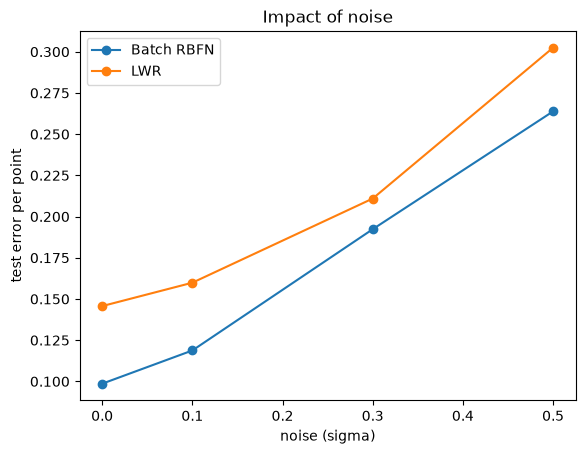

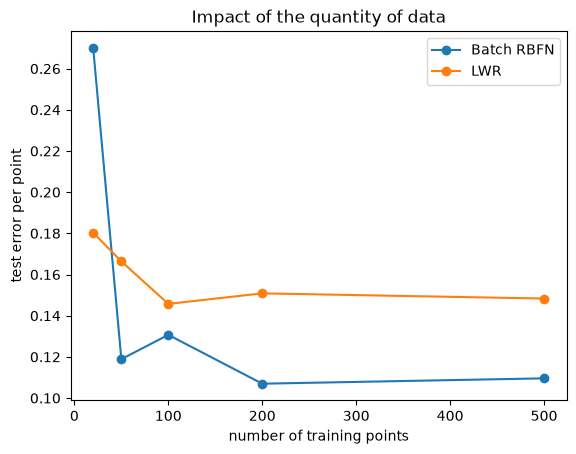

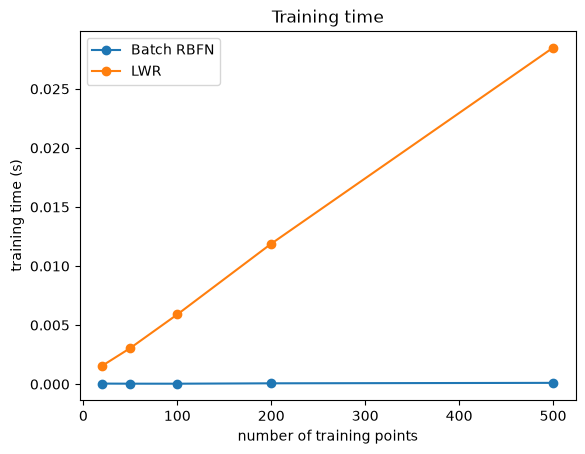

Points kept: 82 out of 100
RBFN test error: 0.19522079822167146


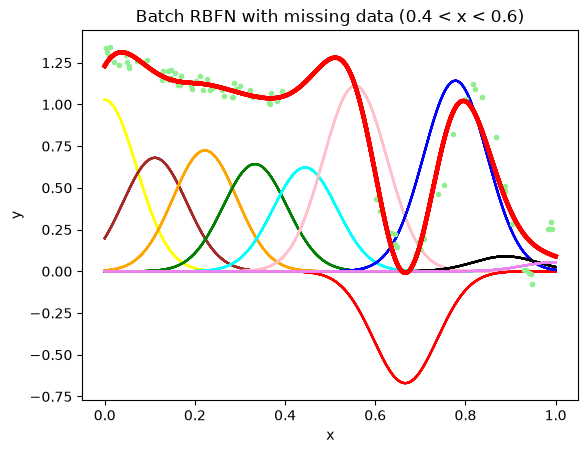

LWR test error: 0.1494148013263307


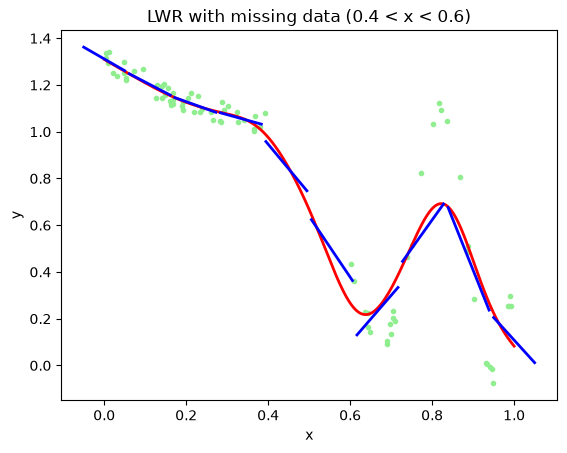

In [39]:
# Optional study 1: Batch RBFNs versus LWR

nb_features = 10
lf = NonLinearLatentFunction()

# Batch di test senza rumore (stessa funzione lf)
lf.sigma = 0
N_test = 500
test_batch = lf.get_batch(N_test)

# Noise impact
sigmas = [0, 0.1, 0.3, 0.5]
errors_rbfn, errors_lwr = [], []

for s in sigmas:
    lf.sigma = s
    batch = lf.get_batch(100)

    model = BatchRBFN1(nb_features)
    model.train(batch.x_data, batch.y_data)
    errors_rbfn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = LWR(nb_features)
    model.train(batch.x_data, batch.y_data)
    errors_lwr.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(sigmas, errors_rbfn, 'o-', label="Batch RBFN")
plt.plot(sigmas, errors_lwr, 'o-', label="LWR")
plt.xlabel("noise (sigma)"); plt.ylabel("test error per point")
plt.title("Impact of noise")
plt.legend()
plt.show()

# Impact of Data quantity
lf.sigma = 0.1
sizes = [20, 50, 100, 200, 500]
errors_rbfn, errors_lwr, times_rbfn, times_lwr = [], [], [], []

for size in sizes:
    batch = lf.get_batch(size)

    model = BatchRBFN1(nb_features)
    start = time.process_time()
    model.train(batch.x_data, batch.y_data)
    times_rbfn.append(time.process_time() - start)
    errors_rbfn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    model = LWR(nb_features)
    start = time.process_time()
    model.train(batch.x_data, batch.y_data)
    times_lwr.append(time.process_time() - start)
    errors_lwr.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(sizes, errors_rbfn, 'o-', label="Batch RBFN")
plt.plot(sizes, errors_lwr, 'o-', label="LWR")
plt.xlabel("number of training points"); plt.ylabel("test error per point")
plt.title("Impact of the quantity of data")
plt.legend()
plt.show()

plt.plot(sizes, times_rbfn, 'o-', label="Batch RBFN")
plt.plot(sizes, times_lwr, 'o-', label="LWR")
plt.xlabel("number of training points"); plt.ylabel("training time (s)")
plt.title("Training time")
plt.legend()
plt.show()

#
lf.sigma = 0.1
batch = lf.get_batch(100)

x_gap, y_gap = [], []
for i in range(len(batch.x_data)):
    if batch.x_data[i] < 0.4 or batch.x_data[i] > 0.6:
        x_gap.append(batch.x_data[i])
        y_gap.append(batch.y_data[i])
x_gap = np.array(x_gap)
y_gap = np.array(y_gap)
print("Points kept:", len(x_gap), "out of", len(batch.x_data))

model = BatchRBFN1(nb_features)
model.train(x_gap, y_gap)
print("RBFN test error:", model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))
model.plot(x_gap, y_gap, "Batch RBFN with missing data (0.4 < x < 0.6)")

model = LWR(nb_features)
model.train(x_gap, y_gap)
print("LWR test error:", model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))
model.plot(x_gap, y_gap, "LWR with missing data (0.4 < x < 0.6)")


# Comment:
# Noise: for both models the test error increases with the noise, since part
# of the noise is learned by the model. The batch RBFN is generally more precise
# than LWR, because with the same number of features LWR combines straight lines
# and struggles to follow sharp variations of the function (e.g. narrow peaks).
#
# Quantity of data: with more data the error decreases and then stabilizes for
# both models. With very few points the batch RBFN is less stable and LWR is
# more robust, while with enough data the RBFN gives a lower error.
#
# Training time: the batch RBFN is much faster and almost constant, since it
# solves a single least squares problem with vectorized operations. The LWR time
# grows with the number of points, because of its Python loops over features and points.
#
# Missing data: in the empty region the batch RBFN behaves badly, because the
# Gaussians placed there have no data and the curve can oscillate. LWR handles
# the gap better: its local lines extend outside their data and blend smoothly,
# giving a lower test error. RBFNs combine flat basis functions, while LWR
# combines local linear models, which interpolate better where data is missing.



### Optional study 2: Incremental RBFNs versus neural networks

By using the same batches of data and tuning your models depending on these batches, compare the performance
and training time of incremental RBFNs and neural networks under various training regimes.
 Change the amount of noise, the quantity of data, or study the impact of missing data.

[0.94558359 0.41295195 0.73831379 0.56281553 0.52150881 0.86778304
 0.79045067 0.76620525 0.55430932 0.6458751 ]
Loss after iteration   500: 37.529
[0.33046105 0.13100241 0.7263054  0.30718976 0.14450806 0.59280621
 0.31705083 0.80156094 0.21449901 0.71544971]
Loss after iteration   500: 76.723
[0.07936204 0.44129877 0.97594804 0.06385618 0.05385388 0.09411874
 0.46028676 0.96982436 0.55965217 0.54824976]
Loss after iteration   500: 96.031
[0.17985953 0.82766878 0.25684089 0.74645638 0.57605214 0.33416399
 0.97349435 0.70673991 0.16741016 0.28081292]
Loss after iteration   500: 113.877


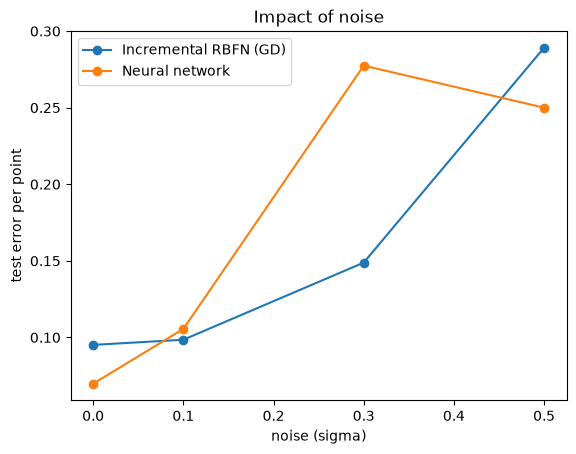

[0.38059661 0.55486152 0.84797366 0.5015766  0.35882515 0.24724626
 0.94743368 0.75506056 0.92389767 0.59054207]
Loss after iteration   500: 32.043
[0.27093042 0.08386122 0.30087188 0.97611757 0.32353704 0.48573629
 0.12260382 0.30018496 0.26391522 0.11531272]
Loss after iteration   500: 73.983
[0.09945326 0.78410466 0.08235641 0.41299293 0.88225128 0.49927137
 0.45500699 0.17970967 0.36622299 0.67977063]
Loss after iteration   500: 93.241
[0.19989059 0.48184361 0.63330589 0.75024082 0.24152256 0.54557639
 0.85266323 0.66516888 0.75885616 0.07334683]
Loss after iteration   500: 274.825
[0.53052861 0.16226765 0.90871722 0.65190244 0.96199089 0.25928468
 0.63251263 0.73887895 0.58910542 0.53179651]
Loss after iteration   500: 120.670


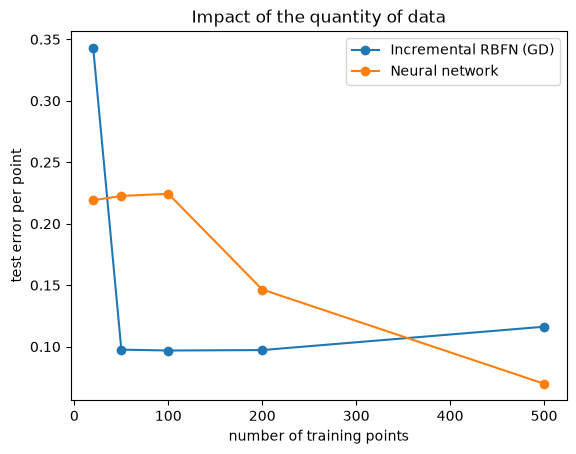

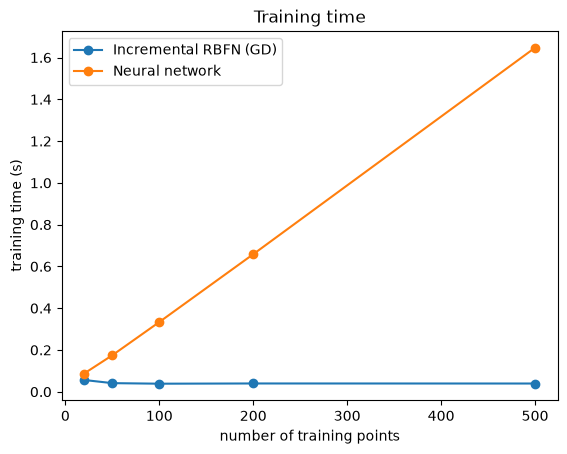

Points kept: 73 out of 100
[0.21120389 0.50807894 0.46586479 0.12910225 0.9750602  0.95100192
 0.23669309 0.50042221 0.99748091 0.26297976]
RBFN test error: 0.173857984700401


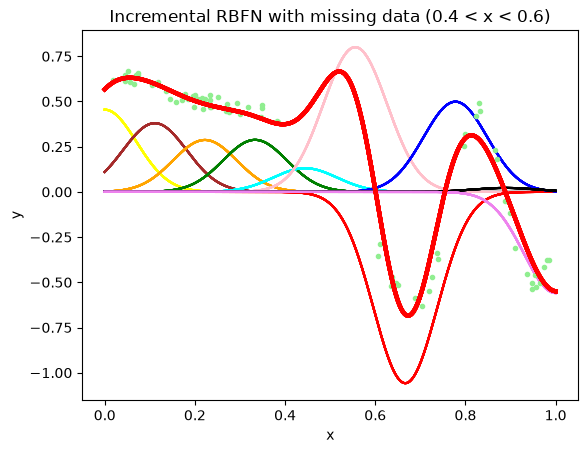

Loss after iteration   500: 83.327
NN test error: 0.10293104784157736


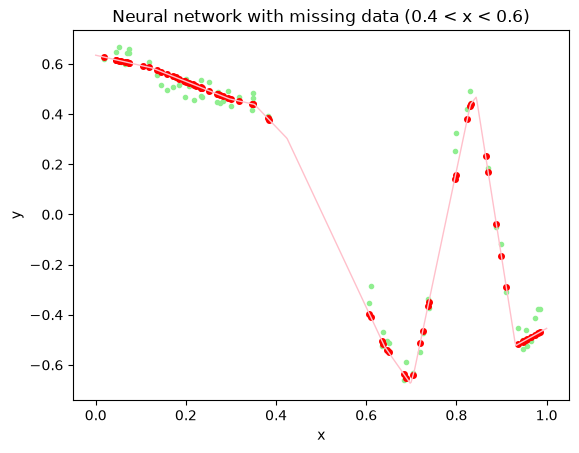

In [41]:
# Optional study 2: Incremental RBFNs versus neural networks

# Settings
nb_features = 10          
alpha = 0.5        
max_iter = 5000          
n_epochs = 500           
lf = NonLinearLatentFunction()

# Test batch without noise
N_test = 500
test_batch = lf.get_batch(N_test)

# Impact of noise
sigmas = [0, 0.1, 0.3, 0.5]
errors_rbfn, errors_nn = [], []

for s in sigmas:
    lf.sigma = s
    batch = lf.get_batch(100)

    # Incremental RBFN
    model = GDRBFN(nb_features)
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha)
    errors_rbfn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    # Neural network, mini-batches of 25 points 
    train_data = NonLinearRegressionData(batch.x_data, batch.y_data)
    train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
    model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)
    train(n_epochs, n_epochs)
    errors_nn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(sigmas, errors_rbfn, 'o-', label="Incremental RBFN (GD)")
plt.plot(sigmas, errors_nn, 'o-', label="Neural network")
plt.xlabel("noise (sigma)"); plt.ylabel("test error per point")
plt.title("Impact of noise")
plt.legend()
plt.show()

# Impact of the quantity of data 
lf.sigma = 0.1
sizes = [20, 50, 100, 200, 500]
errors_rbfn, errors_nn, times_rbfn, times_nn = [], [], [], []

for size in sizes:
    batch = lf.get_batch(size)

    model = GDRBFN(nb_features)
    start = time.process_time()
    for _ in range(max_iter):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha)
    times_rbfn.append(time.process_time() - start)
    errors_rbfn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

    train_data = NonLinearRegressionData(batch.x_data, batch.y_data)
    train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
    model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)
    start = time.process_time()
    train(n_epochs, n_epochs)
    times_nn.append(time.process_time() - start)
    errors_nn.append(model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))

plt.plot(sizes, errors_rbfn, 'o-', label="Incremental RBFN (GD)")
plt.plot(sizes, errors_nn, 'o-', label="Neural network")
plt.xlabel("number of training points"); plt.ylabel("test error per point")
plt.title("Impact of the quantity of data")
plt.legend()
plt.show()

plt.plot(sizes, times_rbfn, 'o-', label="Incremental RBFN (GD)")
plt.plot(sizes, times_nn, 'o-', label="Neural network")
plt.xlabel("number of training points"); plt.ylabel("training time (s)")
plt.title("Training time")
plt.legend()
plt.show()

# Missing data
lf.sigma = 0.1
full_batch = lf.get_batch(100)

kept = 0
for i in range(full_batch.size):
    if full_batch.x_data[i] < 0.4 or full_batch.x_data[i] > 0.6:
        kept = kept + 1

# Build a new batch 
gap_batch = Batch(kept)
for i in range(full_batch.size):
    if full_batch.x_data[i] < 0.4 or full_batch.x_data[i] > 0.6:
        gap_batch.add_sample(full_batch.x_data[i], full_batch.y_data[i])
print("Points kept:", kept, "out of", full_batch.size)

model = GDRBFN(nb_features)
for _ in range(max_iter):
    x, y = gap_batch.get_random_sample()
    model.train(x, y, alpha)
print("RBFN test error:", model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))
model.plot(gap_batch.x_data, gap_batch.y_data, "Incremental RBFN with missing data (0.4 < x < 0.6)")

train_data = NonLinearRegressionData(gap_batch.x_data, gap_batch.y_data)
train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)
train(n_epochs, n_epochs)
print("NN test error:", model.compute_error(test_batch.x_data, test_batch.y_data) / np.sqrt(N_test))
model.plot(gap_batch.x_data, gap_batch.y_data, "Neural network with missing data (0.4 < x < 0.6)")



# Comment:
# Noise: for both models the test error increases with the noise, since part
# of the noise is learned during training.
#
# Precision: the neural network usually approximates the function better,
# because its hidden layers learn their own features. The incremental RBFN is
# limited by its fixed Gaussians and by gradient descent, which approaches the
# optimal solution slowly.
#
# Quantity of data: more data generally reduces the error for both models.
# The RBFN training time is almost constant, since it always performs the same
# number of updates (one sample each). The network training time grows with the
# data, because each epoch is a full pass over all the points.
#
# Missing data: in the empty region the RBFN can oscillate, because the
# Gaussians placed there receive no data. The network with ReLU tends to connect
# the two sides with almost linear pieces, giving a smoother result.
#
# Note: the two models use different training budgets (number of updates vs
# number of epochs), so the comparison of training times should be read with care.

